# Leyenda: Deliverable 1, Binary classification (photo vs. other)

**Client:** TouNum (document digitization) · **Team:** CESI Data Science · **Module 1 of 3**

## 1. Business context

TouNum digitizes paper archives in bulk for its clients. It wants to add a machine-learning service that
**automatically writes a caption for each photograph** in a digitized archive. The full workflow has three modules:

```
 digitized archive ──► [1] PHOTO FILTER ──► [2] DENOISING ──► [3] CAPTIONING ──► captioned photos
   (mixed images)       photo / other         conv. autoencoder   CNN encoder + RNN decoder
                          │
                          └──► non-photos (text scans, diagrams, drawings, paintings): set aside
```

Archives contain far more than photos: scanned text pages, diagrams, drawings and paintings. A captioning
model trained on photographs produces meaningless captions for these images. **This notebook builds module 1**,
a neural network that keeps only the photos.

**What an error costs TouNum:**

| Error | Consequence | Metric |
|---|---|---|
| A photo is rejected (false negative) | The photo never gets a caption: lost value for the client | **Recall** (photo) |
| A non-photo is accepted (false positive) | A wrong caption is delivered: hurts credibility | **Precision** (photo) |

We track both through the **F1-score**, plus **ROC-AUC**, which doesn't depend on a decision threshold. Each model
is also measured **per image source**, because rejecting a scanned text page is easy while rejecting a realistic
painting is much harder.

**Method.** As the brief advises, we start with the easiest distinctions (photo vs. text and diagrams) and move to
the hardest one (photo vs. painting). We improve the model through a sequence of **tracked experiments**. Every
attempt, including the failures, is logged with its hypothesis, curves and verdict; section 9 gathers them into the
training journal.

## 2. Setup

In [1]:
import leyenda                      # import before TensorFlow: pre-loads the CUDA libraries (GPU fix)
# The notebook kernel stays on CPU: every training runs in its own process on the GPU (see section 6).
leyenda.setup(seed=42, gpu=False)

import inspect, json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display, Markdown

from leyenda.env import DATA_DIR, MODELS_DIR, REPORTS_DIR, RUNS_DIR
from leyenda.data import build_index, clean_index, split, class_weights, make_dataset, show_samples, fixed_benchmark
from leyenda import models as M
from leyenda.evaluation import (predict, binary_metrics, per_category_report, plot_confusion,
                                plot_errors, plot_architecture)
from leyenda.tracking import Run, plot_curves, plot_runs, training_journal

DELIVERABLE = "d1_classifier"
IMG = 160          # input resolution (benchmarked: fits the 2 GB GPU, and MobileNetV2 has ImageNet weights at 160)
RETRAIN = False    # False: reuse finished experiments from runs/ (notebook re-runs in minutes); True: retrain all
CACHE = DATA_DIR / "processed" / "tfcache"
pd.set_option("display.precision", 3)

TensorFlow 2.21.0 | Keras 3.15.1 | seed=42
GPU: none (CPU only) | precision policy: float32


E0000 00:00:1791915164.861713  346625 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1791915164.866233  346625 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1791915164.866448  346625 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.


## 3. Data audit

TouNum provided 5 archives. They aren't labelled image by image, but **the archive (folder) is the label**:
`Photo` → class 1, everything else → class 0. Before training, we check what the data actually contains:
corrupt files, formats, sizes and duplicates.

In [2]:
INDEX = DATA_DIR / "processed" / "index_raw.csv"
if INDEX.exists():
    raw = pd.read_csv(INDEX)
else:  # ~20 s: reads every file, computes an MD5 hash, verifies it decodes
    raw = build_index()
    raw.to_csv(INDEX, index=False)

summary = raw.groupby("category").agg(
    images=("path", "size"), size_MB=("bytes", lambda b: b.sum() / 1e6),
    unreadable=("readable", lambda r: int((~r).sum())),
    median_width=("width", "median"), median_height=("height", "median"),
    min_side=("width", lambda w: int(np.minimum(w, raw.loc[w.index, "height"]).min())))
summary["label"] = np.where(summary.index == "Photo", "photo (1)", "other (0)")
display(summary)
display(pd.crosstab(raw["category"], raw["mode"]).rename_axis(columns="colour mode"))

,images,size_MB,unreadable,median_width,median_height,min_side,label
category,,,,,,,
Painting,9999,4654.652,0,800.0,800.0,201,other (0)
Photo,9993,1630.995,0,640.0,480.0,109,photo (1)
Schematics,5051,390.242,0,679.0,467.0,1,other (0)
Sketch,1406,49.773,0,1111.0,1111.0,411,other (0)
Text,10000,702.081,0,595.0,842.0,360,other (0)


colour mode,CMYK,L,P,RGB,RGBA
category,,,,,
Painting,1,82,5,9906,5
Photo,0,25,0,9968,0
Schematics,0,64,0,4987,0
Sketch,0,868,0,538,0
Text,0,0,0,10000,0


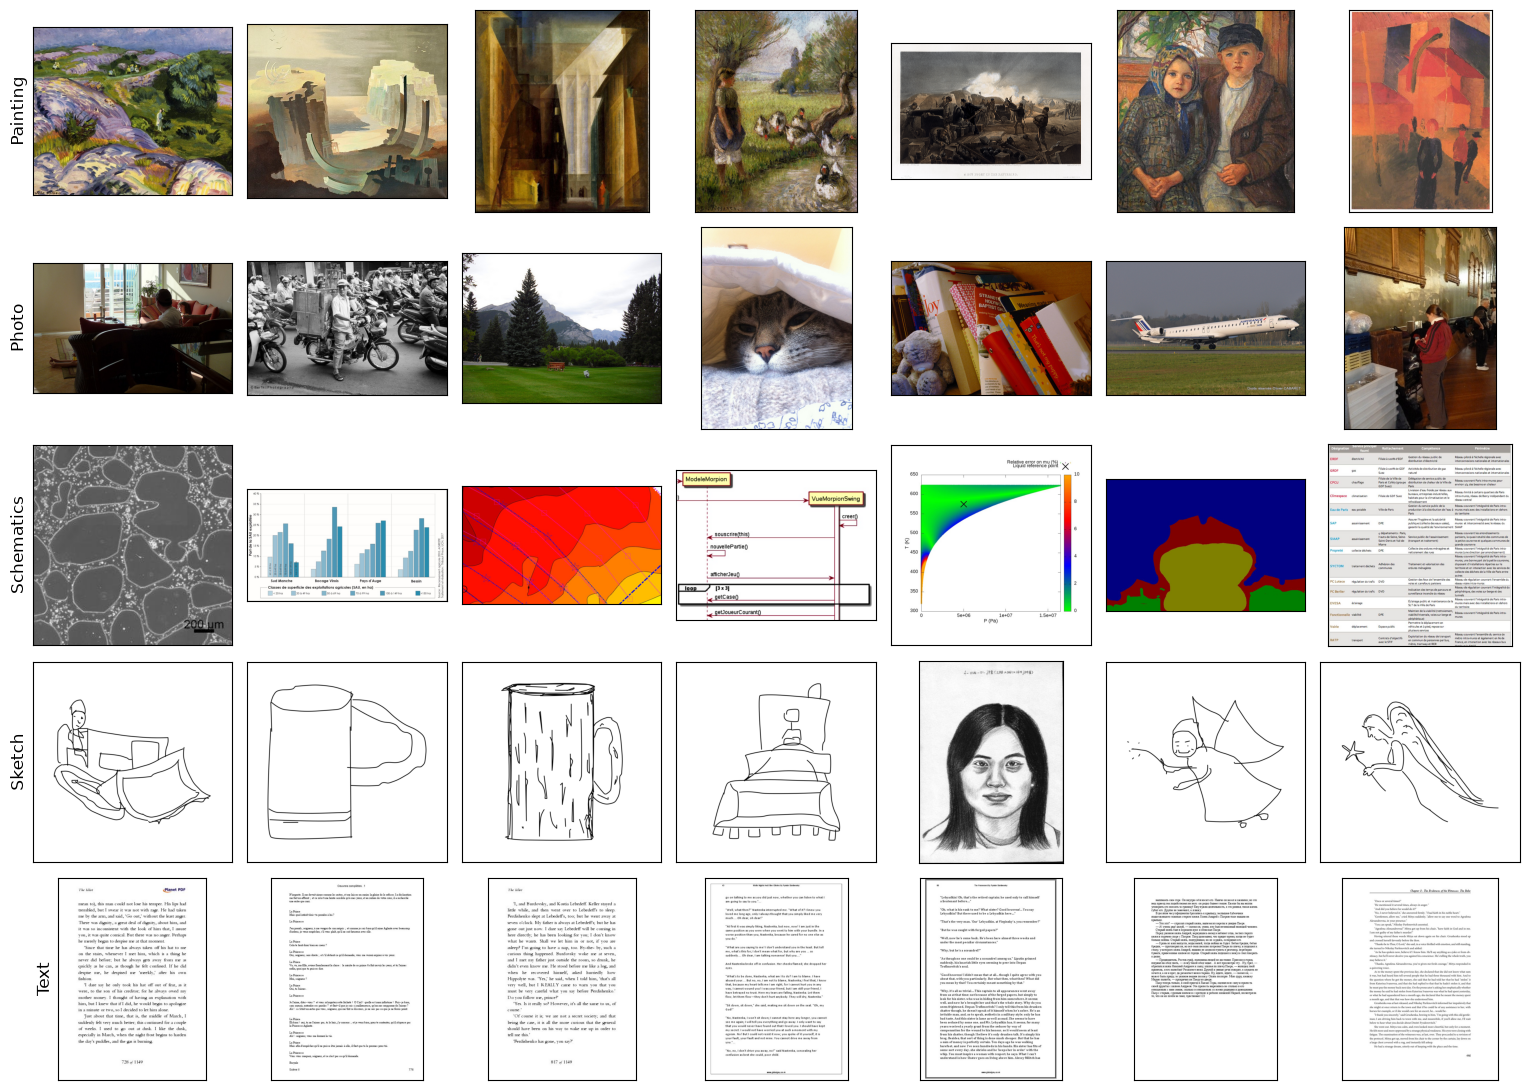

In [3]:
show_samples(raw[raw["readable"]], n=7)

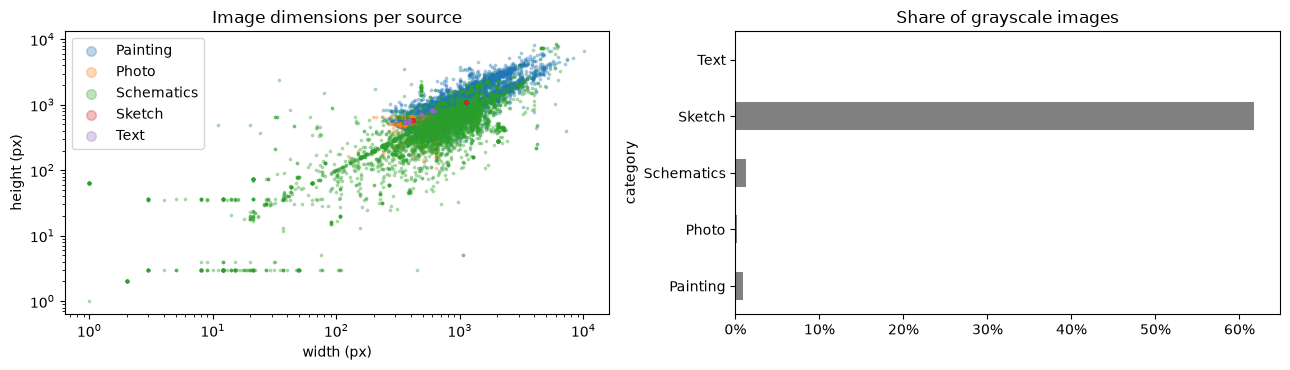

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for cat, g in raw.groupby("category"):
    axes[0].scatter(g["width"], g["height"], s=3, alpha=0.3, label=cat)
axes[0].set(xscale="log", yscale="log", xlabel="width (px)", ylabel="height (px)", title="Image dimensions per source")
axes[0].legend(markerscale=4)
gray = raw.assign(grayscale=raw["mode"].isin(["L", "P"])).groupby("category")["grayscale"].mean()
gray.plot.barh(ax=axes[1], color="grey", title="Share of grayscale images")
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

**Audit findings**

1. **No corrupt files.** Every image decodes.
2. **Mixed colour formats** (grayscale `L`, palette `P`, `CMYK`, `RGBA`). The pipeline converts everything to
   3-channel RGB.
3. **Very different sizes per source.** Photos are at most 640 px wide, Sketches are all 1111×1111 and Text pages
   have the A4 shape. Every image is resized to 160×160, so absolute size can't be used as a cue, but this
   reminds us that **each source has a "signature" a model could exploit**.
4. **Shortcut risk:** most Sketches are grayscale, while photos are almost all in colour. A model could learn
   "grayscale ⇒ not a photo", which would be disastrous for TouNum's old black-and-white photos.
   **We test this explicitly in section 8.**
5. **Debris in Schematics:** several hundred images only a few pixels wide (colour-bar strips, 1-px slivers,
   fragments left over from extracting figures out of PDFs), plus exact duplicates.

## 4. Cleaning and train / validation / test split

* Images whose shorter side is **under 32 px** are removed: once resized to 160×160 they carry no information,
  and some are fragments of photos labelled as diagrams (wrong labels).
* **Exact duplicates** (same MD5 hash) are removed. Otherwise the same image could land in both train and test
  and inflate the scores (data leakage).
* Split 70 / 15 / 15, **stratified by source** rather than just by class, so that paintings, sketches and so on
  keep the same proportion in each split. The split is saved to a file, so it's reproducible.
* **Validation** is used to compare experiments. The **test** set is used **only once**, for the final model
  (section 7).

In [5]:
clean, removed = clean_index(raw, min_side=32)
display(removed.groupby(["reason", "category"]).size().rename("removed").to_frame())

SPLIT = DATA_DIR / "processed" / "d1_split.csv"
if SPLIT.exists():
    data = pd.read_csv(SPLIT)
else:
    data = split(clean, val=0.15, test=0.15, seed=42)
    data.to_csv(SPLIT, index=False)

train_df, val_df, test_df = (data[data["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))
display(pd.crosstab(data["category"], data["split"], margins=True)[["train", "val", "test", "All"]])

CW = class_weights(train_df["label"])
print(f"photo share in train: {train_df['label'].mean():.1%}  ->  class weights {{other: {CW[0]:.2f}, photo: {CW[1]:.2f}}}")

removed
reason                    category           
duplicate within category Painting          4
                          Schematics      150
                          Text              1
smaller than 32px         Schematics      335

split,train,val,test,All
category,,,,
Painting,6997,1499,1499,9995
Photo,6995,1499,1499,9993
Schematics,3196,685,685,4566
Sketch,984,211,211,1406
Text,6999,1500,1500,9999
All,25171,5394,5394,35959


photo share in train: 27.8%  ->  class weights {other: 0.69, photo: 1.80}


**Class imbalance.** Photos make up only about 28% of the data. A model that always answered "other" would already
score 72% accuracy. That's why we (1) weight the loss so a photo error costs about 1.8× more, and (2) look at F1,
AUC and per-source results rather than accuracy alone.

## 5. Data pipeline

`tf.data` reads the files, decodes them (JPEG/PNG, any colour mode → RGB), resizes them to 160×160 and keeps the
result in a **disk cache**. Some paintings exceed 8,000 px, so decoding them every epoch would take longer than the
training itself. The first epoch therefore takes longer while it fills the cache.

Images enter the models as raw **0–255 values**. Rescaling and augmentation are **layers inside the model**, so the
exported model can be used directly on raw images in production, with no extra pre-processing code to maintain.

In [6]:
VAL_BS = 64
print(inspect.getsource(make_dataset))
x, y = next(iter(make_dataset(val_df.head(VAL_BS), IMG, VAL_BS)))
print("one batch:", x.shape, x.dtype, "| labels:", y.shape)

def make_dataset(df: pd.DataFrame, img_size: int = 160, batch_size: int = 64, shuffle: bool = False,
                 cache: str | Path | None = None, seed: int = 42):
    """tf.data pipeline: decode (jpg/png, grayscale/RGBA -> RGB) -> resize -> uint8 batches.

    Images stay in [0, 255]; scaling is done inside each model so the saved model accepts raw images.
    `cache` (a file path) stores decoded+resized images on disk after the first epoch, which avoids
    re-decoding multi-megapixel paintings every epoch.
    """
    import tensorflow as tf

    def load(path, label):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        img = tf.image.resize(img, (img_size, img_size), antialias=True)
        return tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8), label

    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values.astype("float32")))
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    if cache:
   

## 6. Experiments

Every experiment follows the same protocol (the `experiment` function below):

1. **Hypothesis** stated *before* training.
2. Training with **binary cross-entropy** as the loss function and **Adam** as the optimizer, weighted by the class
   weights.
3. Automatic logging (`leyenda.tracking.Run`): config, per-epoch curves, architecture diagram, saved model.
4. Evaluation on **validation**: global metrics, **train vs. validation error** (bias/variance), and results per source.
5. **Verdict** (failure / improvement / best) and a lesson that motivates the next experiment.

**Why these choices?**

* **Binary cross-entropy:** the network outputs one probability P(photo) through a sigmoid. BCE is the negative
  log-likelihood of that Bernoulli output, so it heavily penalizes confident mistakes.
* **Adam:** gradient descent with an adaptive learning rate per parameter (momentum plus RMS normalization). It's a
  robust default for CNNs and needs little tuning.

**Technical note: one process per training run.** The 2 GB GPU can't release memory between two models in the
same Python session: memory fragments and the second model crashes with an out-of-memory error. We hit this
ourselves (see the journal). Each experiment is therefore described by a *spec* (architecture plus
hyper-parameters) and trained by `python -m leyenda.train <spec>` in a fresh process that gets the whole GPU.
This is also how TouNum can retrain in production, without a notebook. The model code lives in
`src/leyenda/models.py` and is printed below for every experiment.

In [7]:
print(inspect.getsource(M.compile_binary))

def compile_binary(model: keras.Model, lr: float = 1e-3, jit_compile: bool = False,
                   label_smoothing: float = 0.0) -> keras.Model:
    """Binary cross-entropy = negative log-likelihood of a Bernoulli output: the natural loss for a
    sigmoid classifier. Adam adapts the step size per parameter, a robust default for CNNs.

    jit_compile=False: XLA's convolution autotuner needs scratch GPU memory the 2 GB vGPU does not
    have ("Autotuning failed ... No valid config found"); plain cuDNN kernels work fine."""
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        # label_smoothing > 0 trains towards 1-e/2 and e/2 instead of 1 and 0: less over-confidence on
        # the mislabelled images found in the archives (photos filed as schematics/paintings)
        loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing),
        metrics=["accuracy", keras.metrics.AUC(name="auc"),
                 keras.metrics.Precision(name="precision"), keras.m

In [8]:
def experiment(name, hypothesis, builder, epochs, lr, batch_size, train_sources=None, builder_kwargs=None,
               early_stopping=False, patience=6, deliverable=DELIVERABLE, split_file="d1_split.csv", val=None,
               img_size=IMG, **config):
    val = val_df if val is None else val
    spec = dict(deliverable=deliverable, name=name, hypothesis=hypothesis, builder=builder,
                builder_kwargs=builder_kwargs or {}, epochs=epochs, lr=lr, batch_size=batch_size, img_size=img_size,
                train_sources=train_sources, early_stopping=early_stopping, patience=patience,
                split_file=split_file, **config)
    run = Run(deliverable, name, hypothesis)
    if RETRAIN or not (run.done and (run.dir / "predictions.npz").exists()):
        # train in a fresh process (full GPU), streaming its log here
        proc = subprocess.Popen([sys.executable, "-m", "leyenda.train", json.dumps(spec)],
                                stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in proc.stdout:
            if line.startswith(("Epoch", "[", "TensorFlow", "GPU")) or " - loss" in line or "Error" in line:
                print(line.rstrip())
        if proc.wait() != 0:
            raise RuntimeError(f"training process failed (exit {proc.returncode}); "
                               "re-run this cell to resume from the last checkpoint")
    else:
        print(f"[{run.dir.name}] already trained: reusing saved results (RETRAIN=False)")

    # ---- report -------------------------------------------------------------------------------------
    s = run.summary()
    ev = s["eval_metrics"]
    probs = np.load(run.dir / "predictions.npz", allow_pickle=True)["val"]
    display(Markdown(f"**{run.dir.name}**: {s['params']:,} parameters, {s['epochs_run']} epochs"
                     + (f" (early stopping, best epoch {s.get('best_val_loss_epoch')})" if early_stopping else "")))
    plot_curves(run.history().drop(columns=["epoch"], errors="ignore"),
                title=f"{run.dir.name}: train vs. validation")    # drawn here from the per-epoch log
    table = pd.DataFrame({split: {m: ev[f"{split}_{m}"] for m in ("accuracy", "precision", "recall", "f1", "roc_auc")}
                          for split in ("train", "val")})
    display(table.T.style.format("{:.3f}").set_caption("Train (sample, no augmentation) vs. validation"))
    display(per_category_report(val, probs).style.format({"accuracy": "{:.1%}", "predicted_photo": "{:.1%}"})
            .set_caption("Validation, per source (accuracy = correctly classified)"))
    return run, probs


def show_architecture(run, builder):
    print(inspect.getsource(builder))      # the TensorFlow/Keras code of the architecture
    plot_architecture(run.load_model())    # the diagram, drawn from the trained model

### E1: baseline MLP (fully-connected network)

**Hypothesis.** A dense network on raw pixels, with images downscaled to 64×64 and flattened, is the simplest
possible neural network. It gives us a **baseline**. Because it ignores the 2D structure of the image (a pattern
shifted by one pixel looks completely different to it), we expect a **high-bias** model.

Architecture: `64×64×3 → Flatten (12,288) → Dense 512 ReLU → Dense 128 ReLU → Dense 1 sigmoid`.

[01_mlp_baseline] already trained: reusing saved results (RETRAIN=False)


**01_mlp_baseline**: 6,357,761 parameters, 25 epochs

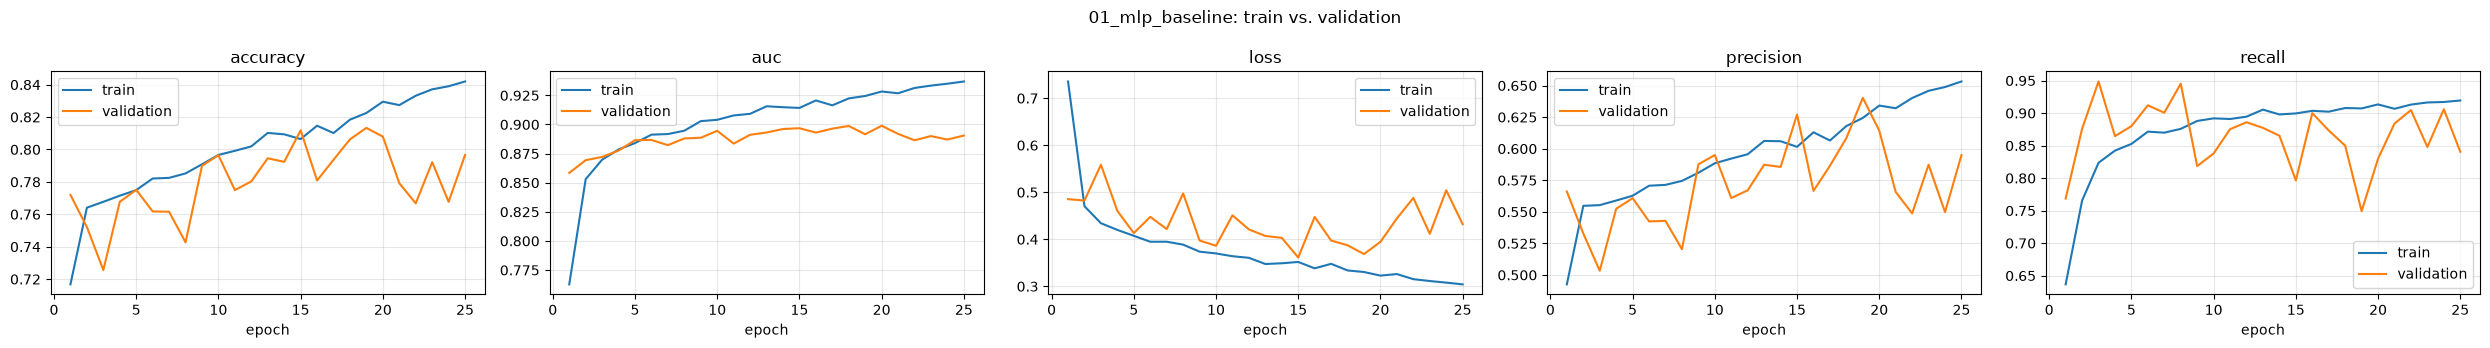

,accuracy,precision,recall,f1,roc_auc
train,0.851,0.667,0.926,0.775,0.947
val,0.797,0.595,0.841,0.697,0.891


,n,accuracy,predicted_photo
category,,,
Painting,1499,51.6%,48.4%
Schematics,685,81.3%,18.7%
Photo,1499,84.1%,84.1%
Sketch,211,98.1%,1.9%
Text,1500,99.9%,0.1%


In [9]:
run_e1, p_e1 = experiment(
    "mlp_baseline", "A fully-connected network on flattened 64x64 pixels can separate photos from other images",
    builder="mlp", epochs=25, lr=1e-3, batch_size=64)

def mlp(img_size: int = 160, input_size: int = 64, hidden=(512, 128)) -> keras.Model:
    """E1 baseline: fully-connected network on flattened downsampled pixels (no spatial prior)."""
    inp = keras.Input((img_size, img_size, 3), name="image")
    x = layers.Resizing(input_size, input_size)(inp)
    x = layers.Rescaling(1 / 255)(x)
    x = layers.Flatten()(x)
    for units in hidden:
        x = layers.Dense(units, activation="relu")(x)
    return keras.Model(inp, _head(x), name="mlp")



/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 14 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(store)


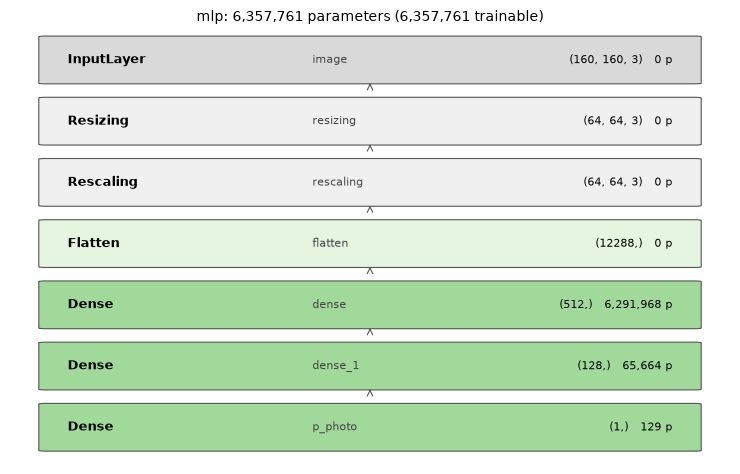

In [10]:
show_architecture(run_e1, M.mlp)

**Analysis: E1 (MLP).** Train accuracy 85.1%, validation 79.7%, F1 0.697, AUC 0.891.

* **High bias:** even on its *own training data* the model stays at 85%. It can't represent the task, because once
  the image is flattened, the network loses all notion of neighbouring pixels, edges and textures.
* Per source: it rejects Text (99.9%) and Sketches (98%) easily, since their pixel statistics (white pages,
  grayscale) are very different from photos. But it rejects only **51.6% of paintings**, no better than a coin toss.
* **Verdict: baseline.** Lesson: we need a model that exploits the 2D structure of images, a **CNN**.

In [11]:
run_e1.annotate("baseline", "High bias: an MLP on flattened pixels cannot fit the task (train 85%). Paintings rejected only 52% of the time -> use a CNN")

### E2: CNN trained only on the "easy" sources

**Hypothesis.** Following the brief, we start with the easiest task: photo vs. **text and diagrams**, whose visual
structure (white background, lines, characters) is very different from a photo. A **convolutional network** suits
this: its filters detect local patterns (edges, textures) wherever they appear, and pooling builds up increasingly
abstract features.

We train **only on Photo + Text + Schematics**, but validate on **all** sources. The question is whether a model
that has never seen a painting or a drawing will still reject them.

Architecture: 4 blocks of `Conv 3×3 (32→64→128→256) + ReLU + MaxPool 2×2` → `Flatten` → `Dense 256` → `sigmoid`.

[02_cnn_easy_sources_only] already trained: reusing saved results (RETRAIN=False)


**02_cnn_easy_sources_only**: 6,942,529 parameters, 15 epochs

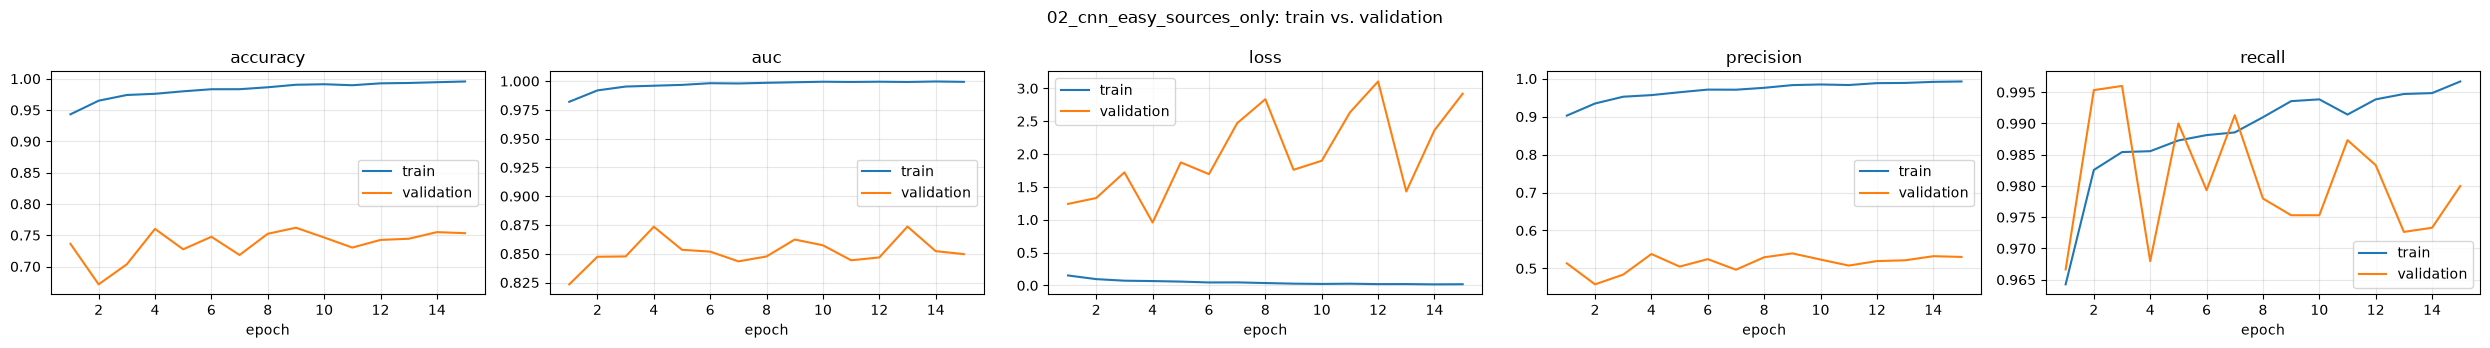

,accuracy,precision,recall,f1,roc_auc
train,0.997,0.995,0.996,0.996,1.000
val,0.753,0.530,0.980,0.688,0.872


,n,accuracy,predicted_photo
category,,,
Painting,1499,15.9%,84.1%
Schematics,685,95.3%,4.7%
Sketch,211,96.2%,3.8%
Photo,1499,98.0%,98.0%
Text,1500,100.0%,0.0%


In [12]:
run_e2, p_e2 = experiment(
    "cnn_easy_sources_only", "A simple CNN trained on photo vs text/schematics generalises to paintings and sketches",
    builder="simple_cnn", epochs=15, lr=1e-3, batch_size=32, train_sources=["Photo", "Text", "Schematics"])

def simple_cnn(img_size: int = 160, filters=(32, 64, 128, 256)) -> keras.Model:
    """E2/E3: plain CNN, no regularisation. Conv blocks extract local patterns (edges, textures),
    pooling makes them translation-tolerant; a dense layer combines them."""
    inp = keras.Input((img_size, img_size, 3), name="image")
    x = layers.Rescaling(1 / 255)(inp)
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    return keras.Model(inp, _head(x), name="simple_cnn")



/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 26 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)


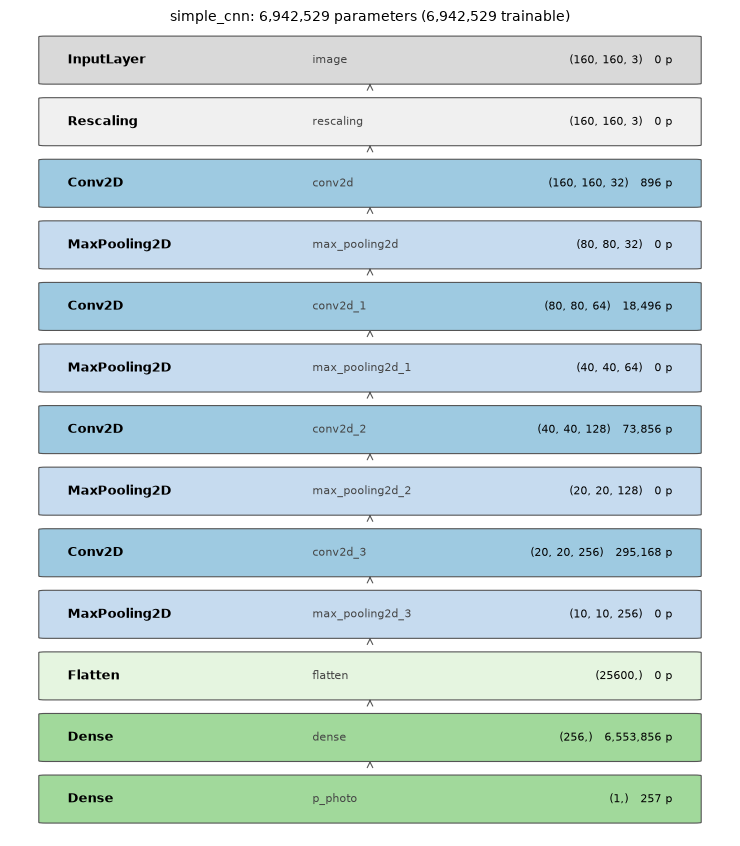

In [13]:
show_architecture(run_e2, M.simple_cnn)

**Analysis: E2 (CNN, easy sources only).** On the sources it trained on, the CNN is almost perfect: training
accuracy **99.7%**, photos 98%, Text 100%, Schematics 95%. But overall validation accuracy falls to **75.3%**.

* It rejects only **15.9% of paintings**: **84% of paintings are classified as photos**.
* The model has learned "photo = anything that is not a document", not "what a photo is". A painting is neither
  text nor a diagram, so it ends up on the photo side.
* **Verdict: failure.** Lesson: **a model only learns the distinctions present in its training data**. The hard
  negatives (paintings, sketches) must be in the training set.

In [14]:
run_e2.annotate("failure", "Trained without paintings/sketches, it calls 84% of paintings photos: a model only learns distinctions present in its training data -> train on all sources")

### E3: same CNN, all sources, no regularization

**Hypothesis.** Adding the hard sources (paintings, sketches) to training will teach the CNN to reject them.
This model has **no regularization** (no dropout, no augmentation, no early stopping), and its
`Flatten → Dense 256` layer alone holds about 6.5 M parameters. We therefore expect **overfitting**, and run 25
epochs on purpose so we can see it.

[03_cnn_all_sources_no_reg] already trained: reusing saved results (RETRAIN=False)


**03_cnn_all_sources_no_reg**: 6,942,529 parameters, 25 epochs

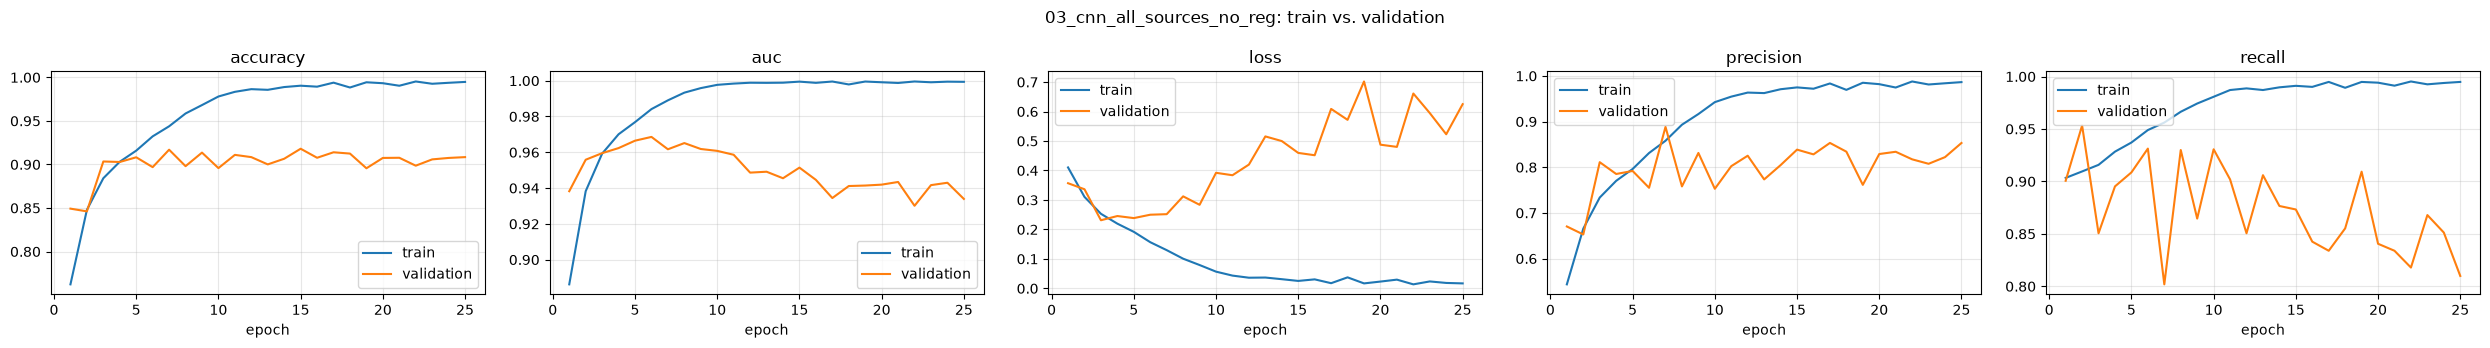

,accuracy,precision,recall,f1,roc_auc
train,0.999,0.999,0.998,0.998,1.000
val,0.908,0.853,0.810,0.831,0.960


,n,accuracy,predicted_photo
category,,,
Photo,1499,81.0%,81.0%
Painting,1499,87.4%,12.6%
Schematics,685,97.1%,2.9%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [15]:
run_e3, p_e3 = experiment(
    "cnn_all_sources_no_reg", "The same CNN trained on all sources learns to reject paintings and sketches",
    builder="simple_cnn", epochs=25, lr=1e-3, batch_size=32)

**Analysis: E3 (CNN, all sources, no regularization).** Validation accuracy **90.8%** (+15.5 points vs. E2),
F1 0.831, AUC 0.960. Paintings are now rejected 87.4% of the time, against 15.9% in E2.

* **But it overfits strongly (high variance).** Training accuracy reaches **99.9%**, a gap of **9 points** with
  validation. On the curves, the training loss keeps falling towards 0 while the **validation loss reaches its
  minimum at epoch 3 (0.23) and then climbs to about 0.6 by epoch 25**: after epoch 3 the network memorizes
  training images instead of learning rules that generalize. Early stopping would have stopped it around epoch 9.
* Cause: the `Flatten → Dense(256)` layer alone holds about 6.5 M weights, enough capacity to memorize 25,000
  images, and nothing in the training prevents it.
* **Verdict: improvement** over E2, but overfitting. Lesson: we need **regularization**.

In [16]:
run_e3.annotate("improvement", "Adding hard sources: F1 0.69 -> 0.83, but train 99.9% vs val 90.8%: high variance (val loss rises while train loss falls) -> regularise")

### E4: regularized CNN

**Hypothesis.** The usual tools to **reduce variance**, used together, will close the train/validation gap from E3:

| Technique | Effect |
|---|---|
| **Data augmentation** (flip, rotation ±18°, zoom, translation) | each epoch sees slightly different images, so the network can't memorize. *No colour changes:* colour is a real cue between photo and painting |
| **Batch Normalization** | stabilizes the distribution of activations, so training is faster and more stable |
| **L2 regularization** (1e-4) | penalizes large weights, giving a smoother decision function |
| **Global Average Pooling** instead of `Flatten` | about 1.2 M parameters in total instead of 7 M |
| **Dropout** 0.4 | randomly turns off 40% of neurons, so the network can't rely on any single one |
| **Early stopping** (patience 6) | stops when validation loss stops improving and restores the best weights |

[04_cnn_regularized] already trained: reusing saved results (RETRAIN=False)


**04_cnn_regularized**: 1,175,393 parameters, 19 epochs (early stopping, best epoch 13)

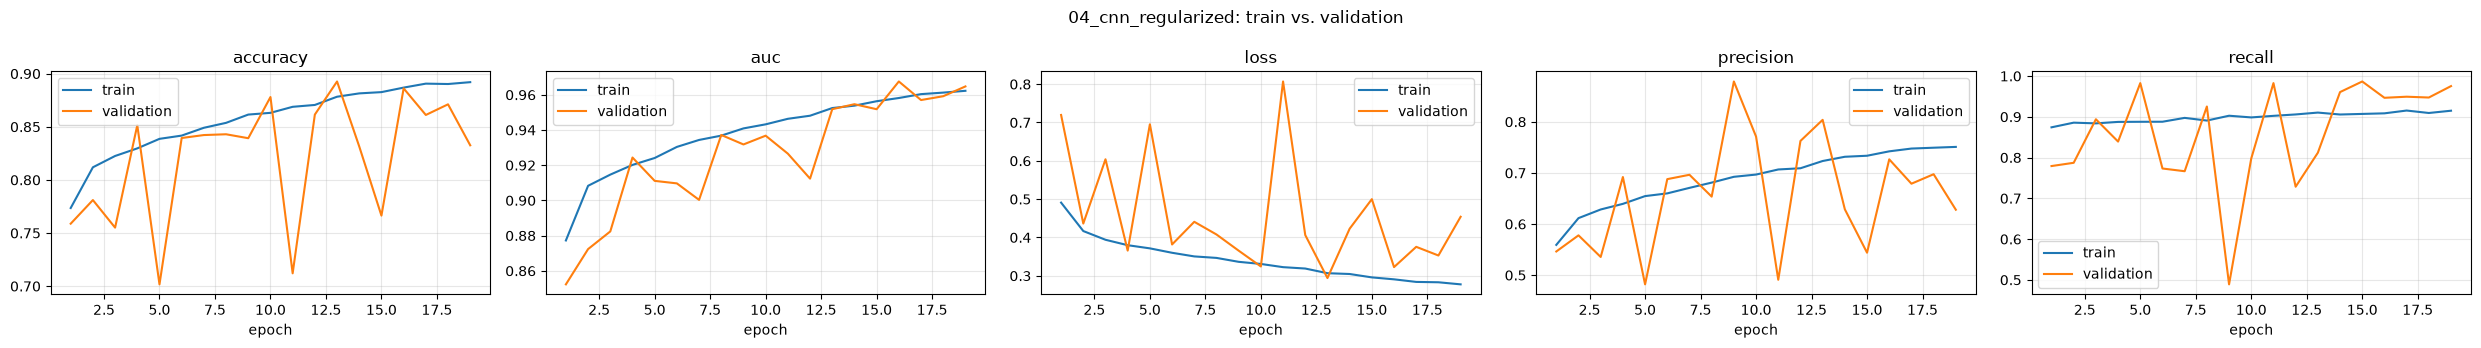

,accuracy,precision,recall,f1,roc_auc
train,0.892,0.792,0.830,0.810,0.951
val,0.893,0.804,0.812,0.808,0.952


,n,accuracy,predicted_photo
category,,,
Photo,1499,81.2%,81.2%
Painting,1499,86.6%,13.4%
Schematics,685,88.6%,11.4%
Sketch,211,91.5%,8.5%
Text,1500,100.0%,0.0%


In [17]:
run_e4, p_e4 = experiment(
    "cnn_regularized", "Augmentation + BatchNorm + L2 + GAP + dropout + early stopping close E3's generalisation gap",
    builder="regularized_cnn", builder_kwargs=dict(l2=1e-4, dropout=0.4), epochs=40, lr=1e-3, batch_size=32,
    early_stopping=True, patience=6, augmentation="flip/rot/zoom/translate")

def augmentation(seed: int = 42, grayscale: float = 0.0) -> keras.Sequential:
    """Only transformations that keep the class: a flipped/rotated/cropped photo is still a photo.
    (No colour jitter: colour statistics are one of the cues separating photos from paintings.)
    grayscale > 0 converts that fraction of training images to black & white, so the model cannot use
    "has colour => photo" as a shortcut and still recognises old black & white photographs."""
    steps = [
        layers.RandomFlip("horizontal", seed=seed),
        layers.RandomRotation(0.05, seed=seed),
        layers.RandomZoom(0.15, seed=seed),
        layers.RandomTranslation(0.1, 0.1, seed=seed),
    ]
    if grayscale:
        steps.append(layers.RandomGrayscale(factor=grayscale, seed=seed))
    return keras.Sequential(steps, name="augmentation")

def regularized_cnn(img_size: int = 160, filters=(32, 64, 128, 256), l2: float = 1e-4,
                    dropout: float = 0.4) -> keras.Model:
    """E4: same d

/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 54 variables whereas the saved optimizer has 58 variables. 
  saveable.load_own_variables(store)


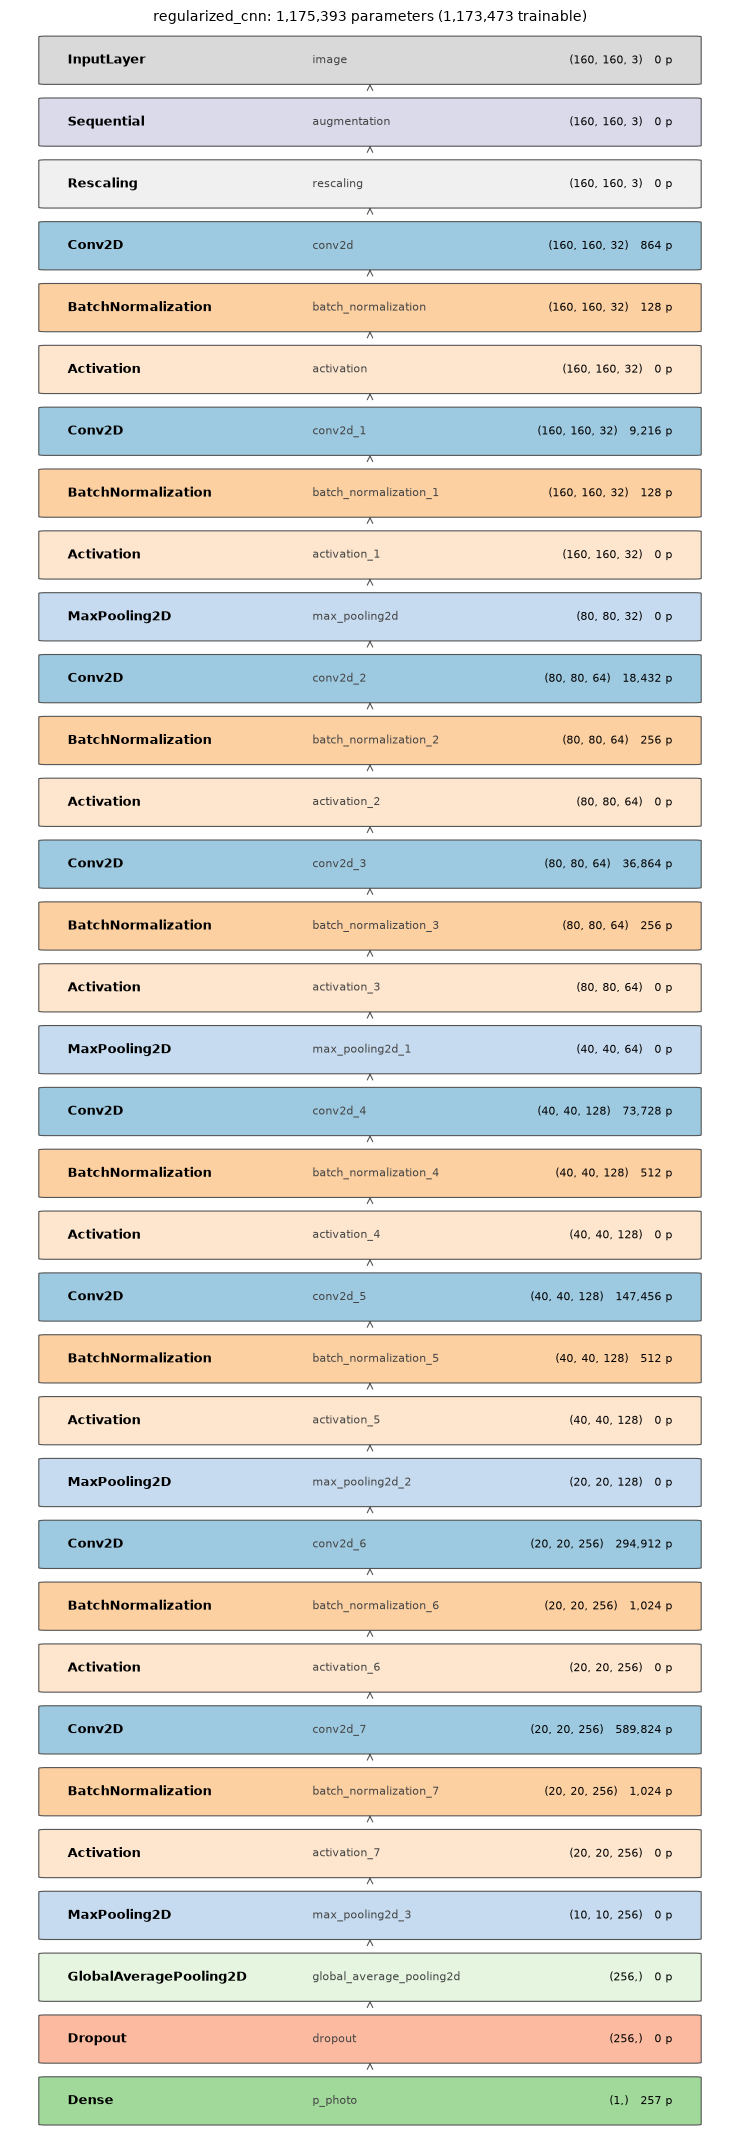

In [18]:
print(inspect.getsource(M.augmentation))
show_architecture(run_e4, M.regularized_cnn)

**Analysis: E4 (regularized CNN).** Training accuracy **89.2%**, validation **89.3%**: **the gap is gone**
(9 points in E3, about 0 here). Regularization did its job against variance. Early stopping ended training at
epoch 19 and restored the weights from epoch 13.

* **But validation F1 (0.808) and AUC (0.952) are slightly *worse* than E3** (0.831 / 0.960), and Schematics
  (88.6%) and Sketches (91.5%) are less well rejected.
* Training accuracy dropped from 99.9% to 89.2%: the model is now **too constrained**. Strong augmentation +
  dropout 0.4 + L2 1e-4 together are too much regularization for a small CNN trained from scratch, so **bias went
  up**. This is the **bias/variance trade-off** in action: lowering variance increased bias.
* The validation curves are also **unstable** (validation accuracy jumped between 70% and 85% in the first
  epochs): BatchNorm statistics estimated on small batches of 32, combined with a fairly high learning rate (1e-3).
* **Verdict: failure on the score, success on variance.** Lessons: (1) regularization settings must be **tuned**,
  not taken as defaults (E4b); (2) a CNN trained from scratch on 25,000 images seems capped around 90%, so we need
  more knowledge than our data contains (transfer learning, E5).

In [19]:
run_e4.annotate("failure", "Gap closed (train 89.2 / val 89.3) but F1 0.808 < E3: over-regularised, bias went up (trade-off). Defaults are not tuned values -> E4b sweep; from-scratch CNN capped ~90% -> transfer learning")

### E4b: tuning the regularization (choosing and improving the settings)

E4's settings (dropout 0.4, L2 1e-4) were **standard defaults, not tuned values**. Regularization is a set of
**hyper-parameters**: the network doesn't learn them, we choose them. The method:

1. Pick the knobs that control regularization strength: here **dropout rate** and **L2 coefficient**.
   Augmentation, BatchNorm, Global Average Pooling and early stopping stay identical, so we change one thing at a time.
2. Try a few values that bracket the current setting, **lighter** this time because E4 showed high bias.
3. Train each one under exactly the same conditions (same data, seed, epochs, early stopping).
4. Compare them **on the validation set** (never on the test set) using F1, and check the train/validation gap.
5. Keep the setting that gives the best validation score without reopening the gap.

| Run | Dropout | L2 | Question it answers |
|---|---|---|---|
| E4 (reference) | 0.4 | 1e-4 | the default setting |
| E4b-1 | 0.2 | 1e-5 | does uniformly lighter regularization reduce bias? |
| E4b-2 | 0.0 | 1e-5 | is dropout needed at all once we have augmentation + BatchNorm? |
| E4b-3 | 0.4 | 0 | is L2 the part that holds the model back? |

#### reg_d02_l2_1e-5: dropout=0.2, L2=1e-05

[07_reg_d02_l2_1e-5] already trained: reusing saved results (RETRAIN=False)


**07_reg_d02_l2_1e-5**: 1,175,393 parameters, 9 epochs (early stopping, best epoch 4)

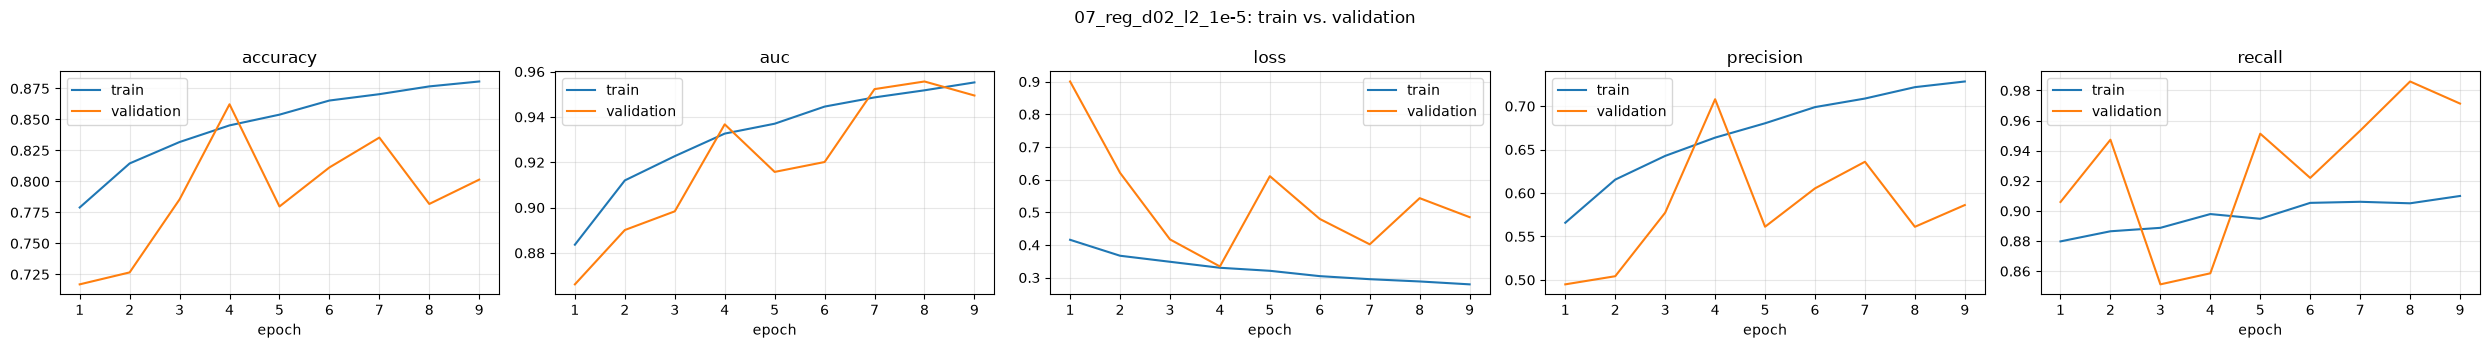

,accuracy,precision,recall,f1,roc_auc
train,0.868,0.710,0.887,0.789,0.939
val,0.862,0.708,0.859,0.776,0.937


,n,accuracy,predicted_photo
category,,,
Painting,1499,70.5%,29.5%
Photo,1499,85.9%,85.9%
Schematics,685,87.3%,12.7%
Sketch,211,99.1%,0.9%
Text,1500,100.0%,0.0%


#### reg_d00_l2_1e-5: dropout=0.0, L2=1e-05

[08_reg_d00_l2_1e-5] already trained: reusing saved results (RETRAIN=False)


**08_reg_d00_l2_1e-5**: 1,175,393 parameters, 8 epochs (early stopping, best epoch 3)

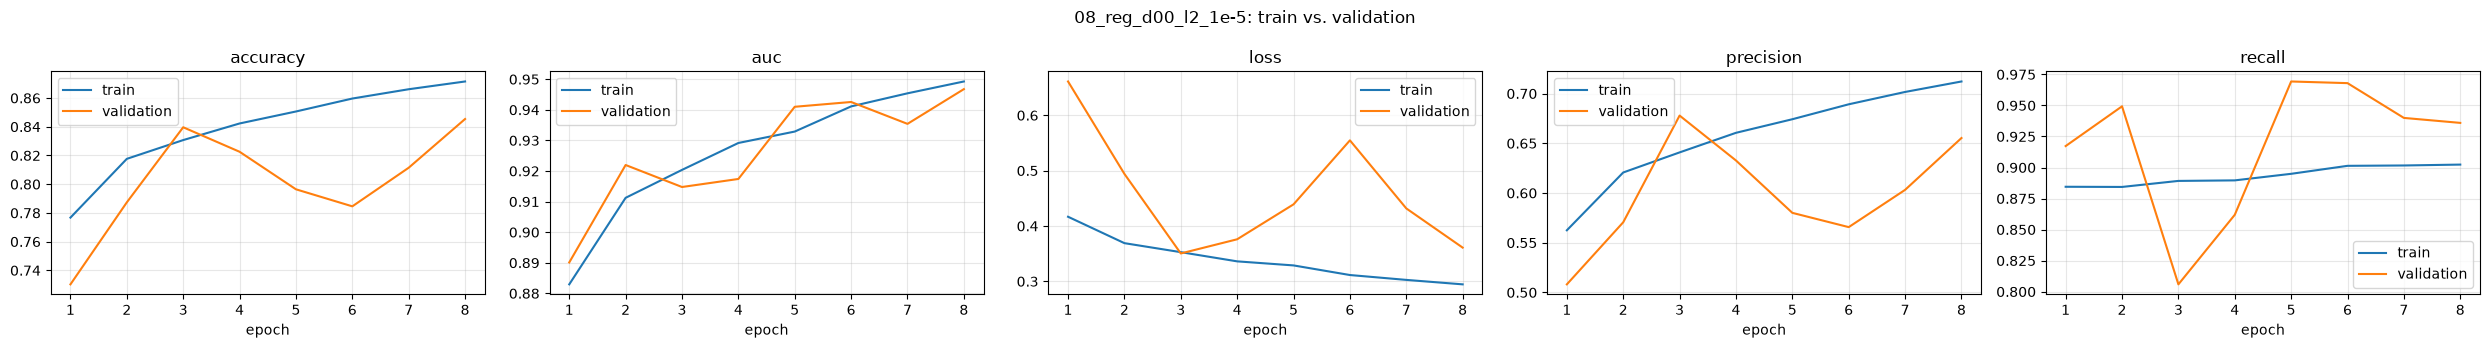

,accuracy,precision,recall,f1,roc_auc
train,0.840,0.674,0.822,0.741,0.918
val,0.840,0.678,0.806,0.736,0.915


,n,accuracy,predicted_photo
category,,,
Painting,1499,66.2%,33.8%
Photo,1499,80.6%,80.6%
Schematics,685,90.1%,9.9%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


#### reg_d04_l2_0: dropout=0.4, L2=0.0

[09_reg_d04_l2_0] already trained: reusing saved results (RETRAIN=False)


**09_reg_d04_l2_0**: 1,175,393 parameters, 15 epochs (early stopping, best epoch 10)

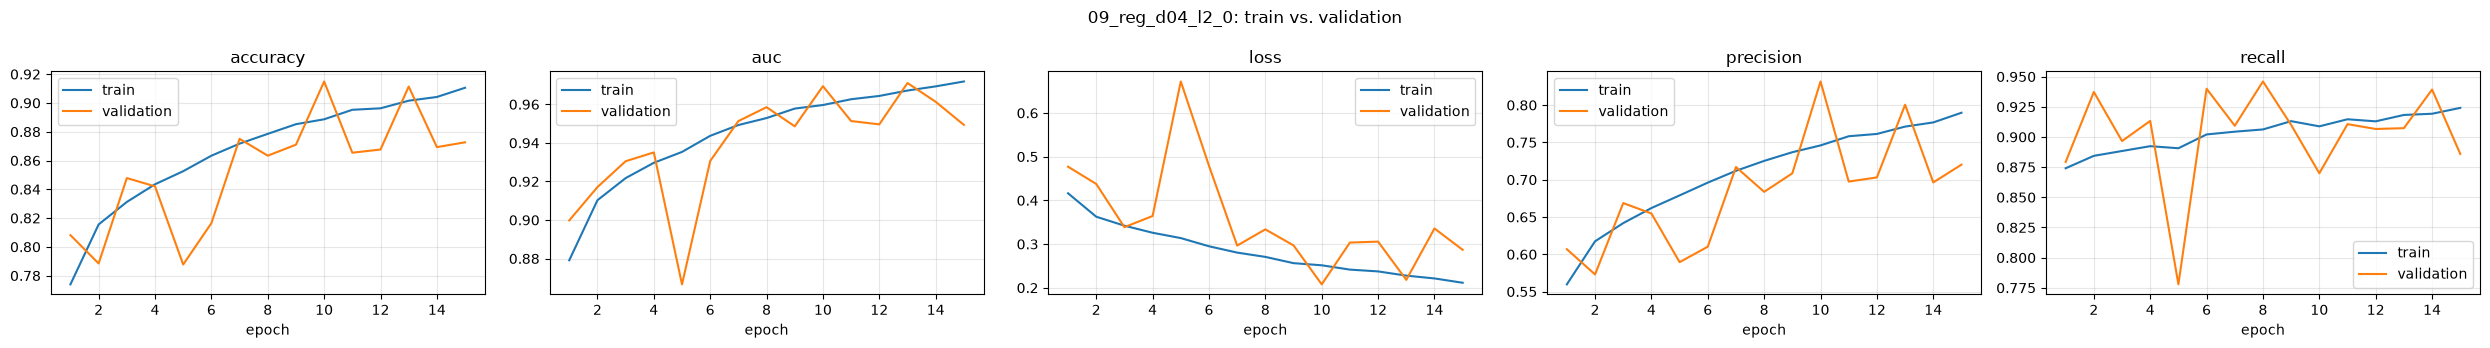

,accuracy,precision,recall,f1,roc_auc
train,0.919,0.829,0.890,0.859,0.972
val,0.915,0.832,0.870,0.850,0.969


,n,accuracy,predicted_photo
category,,,
Painting,1499,85.6%,14.4%
Photo,1499,87.0%,87.0%
Schematics,685,93.0%,7.0%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [20]:
SWEEP = [("reg_d02_l2_1e-5", 0.2, 1e-5), ("reg_d00_l2_1e-5", 0.0, 1e-5), ("reg_d04_l2_0", 0.4, 0.0)]
sweep_runs = {}
for name, dropout, l2 in SWEEP:
    display(Markdown(f"#### {name}: dropout={dropout}, L2={l2}"))
    sweep_runs[name] = experiment(
        name, f"Lighter regularisation (dropout {dropout}, L2 {l2}) than E4 lowers bias while keeping the gap small",
        builder="regularized_cnn", builder_kwargs=dict(dropout=dropout, l2=l2), epochs=30, lr=1e-3, batch_size=32,
        early_stopping=True, patience=5, augmentation="flip/rot/zoom/translate")

,train acc,val acc,gap,val F1,val AUC,epochs
"E3 no reg. (d=0, L2=0, no aug.)",0.999,0.908,0.091,0.831,0.960,25.000000
"E4 d=0.4, L2=1e-4",0.892,0.893,-0.001,0.808,0.952,19.000000
"E4b d=0.2, L2=1e-05",0.868,0.862,0.006,0.776,0.937,9.000000
"E4b d=0.0, L2=1e-05",0.840,0.840,0.000,0.736,0.915,8.000000
"E4b d=0.4, L2=0",0.919,0.915,0.004,0.850,0.969,15.000000


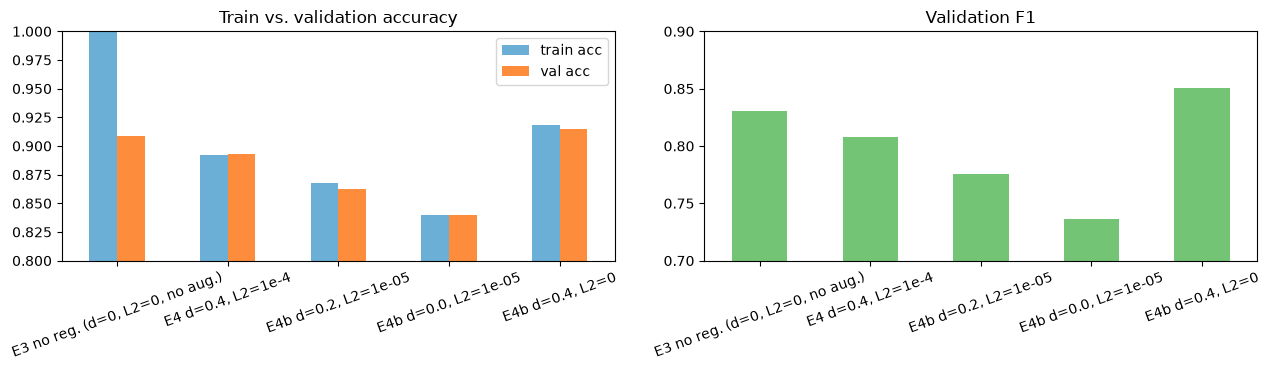

In [21]:
reg_rows = {}
for label, run in [("E3 no reg. (d=0, L2=0, no aug.)", run_e3), ("E4 d=0.4, L2=1e-4", run_e4),
                   *[(f"E4b d={d}, L2={l2:g}", sweep_runs[n][0]) for n, d, l2 in SWEEP]]:
    ev = run.summary()["eval_metrics"]
    reg_rows[label] = {"train acc": ev["train_accuracy"], "val acc": ev["val_accuracy"],
                       "gap": ev["train_accuracy"] - ev["val_accuracy"], "val F1": ev["val_f1"], "val AUC": ev["val_roc_auc"],
                       "epochs": run.summary()["epochs_run"]}
reg_table = pd.DataFrame(reg_rows).T
display(reg_table.style.format({c: "{:.3f}" for c in reg_table.columns if c != "epochs"})
        .highlight_max(subset=["val F1"], color="#c7e9c0").highlight_min(subset=["gap"], color="#deebf7"))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
reg_table[["train acc", "val acc"]].plot.bar(ax=ax[0], color=["#6baed6", "#fd8d3c"], ylim=(0.8, 1.0),
                                             title="Train vs. validation accuracy")
reg_table["val F1"].plot.bar(ax=ax[1], color="#74c476", ylim=(0.7, 0.9), title="Validation F1")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(REPORTS_DIR / "figures" / "d1_regularization_sweep.png", dpi=110); plt.show()

**Analysis: E4b (regularization sweep).**

| Run | Dropout | L2 | Stopped at (best) | Train acc | Val F1 |
|---|---|---|---|---|---|
| E4 | 0.4 | 1e-4 | 19 (13) | 89.2% | 0.808 |
| E4b-1 | 0.2 | 1e-5 | 9 (4) | 86.8% | 0.776 |
| E4b-2 | 0.0 | 1e-5 | 8 (3) | 84.0% | 0.736 |
| **E4b-3** | **0.4** | **0** | 15 (10) | **91.9%** | **0.850** |

1. **The initial hypothesis is rejected.** "Lighter regularization everywhere lowers bias" was false: with less
   dropout (E4b-1, E4b-2), training accuracy went *down*, not up.
2. **The real mechanism shows in the "stopped at" column.** Runs with little or no dropout were stopped by early
   stopping after only 8–9 epochs, with their best epoch at 3–4. Validation loss oscillates strongly from one epoch
   to the next, so early stopping fires on an early "lucky" epoch before the model has finished learning. Dropout
   steadies training and lets it run longer.
3. **L2 was the setting that held the model back.** Removing L2 while keeping dropout 0.4 (E4b-3) gives the **best
   CNN trained from scratch: F1 0.850, AUC 0.969, gap 0.4 point**. It beats E3 (0.831) *without* overfitting
   (E3's gap was 9 points).
4. **Caveat:** one training per setting, and validation loss still oscillates (0.21–0.67 for E4b-3). Differences
   of about ±0.02 F1 are partly noise. The instability itself is the next thing to fix (E4c).

In [22]:
for (name, dropout, l2), verdict, lesson in zip(SWEEP, ["failure", "failure", "improvement"], [
        "Lighter reg. did NOT lower bias: early stopping fired at epoch 9 on oscillating val loss (best ep 4), F1 0.776",
        "No dropout: even earlier stop (epoch 8), F1 0.736 -> dropout also stabilises training",
        "Dropout 0.4 without L2: best from-scratch CNN, F1 0.850 / AUC 0.969, gap 0.4 pt -> L2 was over-constraining. Val loss still oscillates -> LR schedule (E4c)"]):
    sweep_runs[name][0].annotate(verdict, lesson)

### E4c: fixing the unstable training (learning-rate schedule)

**Diagnosis from E4b:** the remaining problem isn't the amount of regularization but **unstable optimization**:
validation loss jumps between epochs, so early stopping triggers too soon.

**Hypothesis.** Keep the best regularization (dropout 0.4, no L2) and change only the optimization:

* **ReduceLROnPlateau:** when validation loss hasn't improved for 3 epochs, **halve the learning rate**
  (down to at least 1e-5). Large steps at the start learn fast; smaller steps later settle into a minimum instead
  of bouncing around it.
* **Early-stopping patience 10** (instead of 5): give the schedule time to act before giving up.

    def callbacks(self, early_stopping: bool = False, patience: int = 5, monitor: str = "val_loss",
                  reduce_lr: bool = False):
        """Keras callbacks for a run. Checkpointing is always on (see _atomic_checkpoint):
        checkpoints/last.keras after every epoch (to resume after a crash) and checkpoints/best.keras
        whenever `monitor` improves. Resuming = load last.keras and call fit(initial_epoch=...)."""
        import shutil
        import keras

        self._ckpt.mkdir(exist_ok=True)
        point = self.resume_point()
        history_csv = self.dir / "history.csv"
        best = float("inf")
        if point is None:  # fresh start: drop anything left by an older attempt of this run
            history_csv.unlink(missing_ok=True)
            shutil.rmtree(self.dir / "tb", ignore_errors=True)
            (self._ckpt / "best.keras").unlink(missing_ok=True)
        else:
            epoch, _ = point
            print(f"[{self.dir.name}] resuming after epoc

**10_reg_d04_l2_0_lr_schedule**: 1,175,393 parameters, 32 epochs (early stopping, best epoch 22)

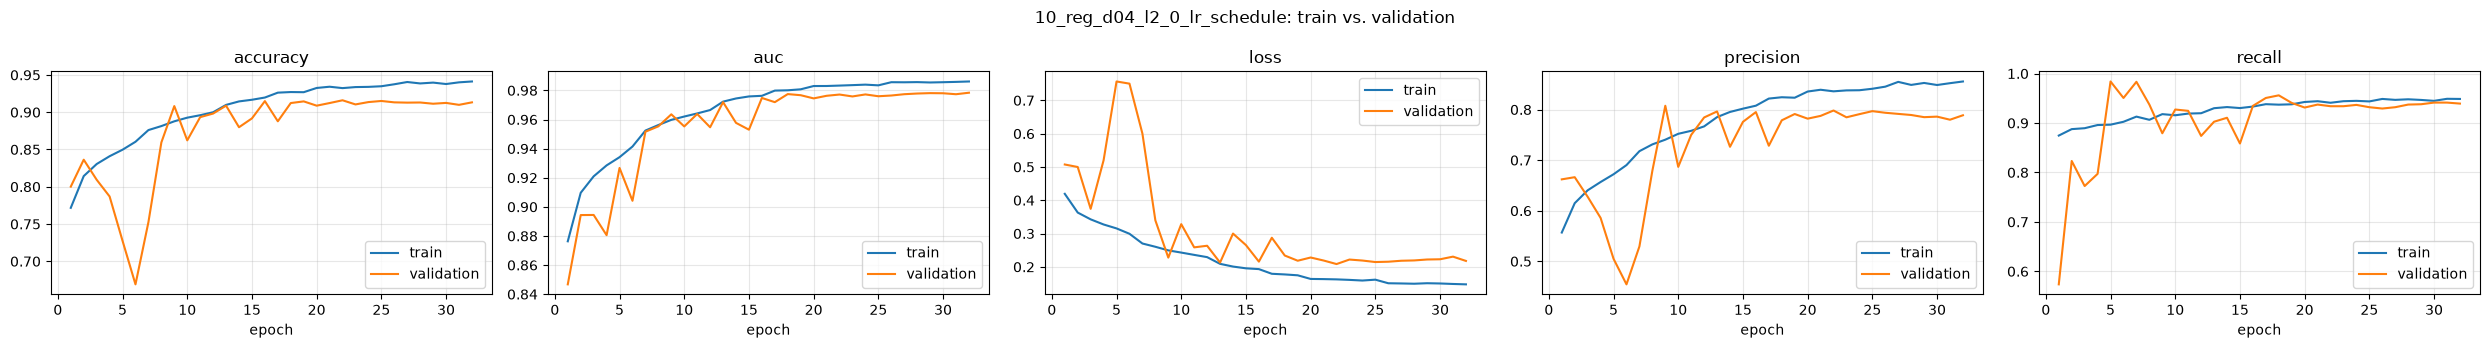

,accuracy,precision,recall,f1,roc_auc
train,0.934,0.829,0.962,0.891,0.985
val,0.916,0.798,0.934,0.861,0.978


,n,accuracy,predicted_photo
category,,,
Painting,1499,78.9%,21.1%
Photo,1499,93.4%,93.4%
Schematics,685,94.7%,5.3%
Sketch,211,99.5%,0.5%
Text,1500,100.0%,0.0%


In [23]:
print(inspect.getsource(Run.callbacks))
run_e4c, p_e4c = experiment(
    "reg_d04_l2_0_lr_schedule",
    "With E4b-3 regularisation, halving the LR on plateau and patience 10 stabilise training and lower bias further",
    builder="regularized_cnn", builder_kwargs=dict(dropout=0.4, l2=0.0), epochs=40, lr=1e-3, batch_size=32,
    early_stopping=True, patience=10, reduce_lr=True, augmentation="flip/rot/zoom/translate")

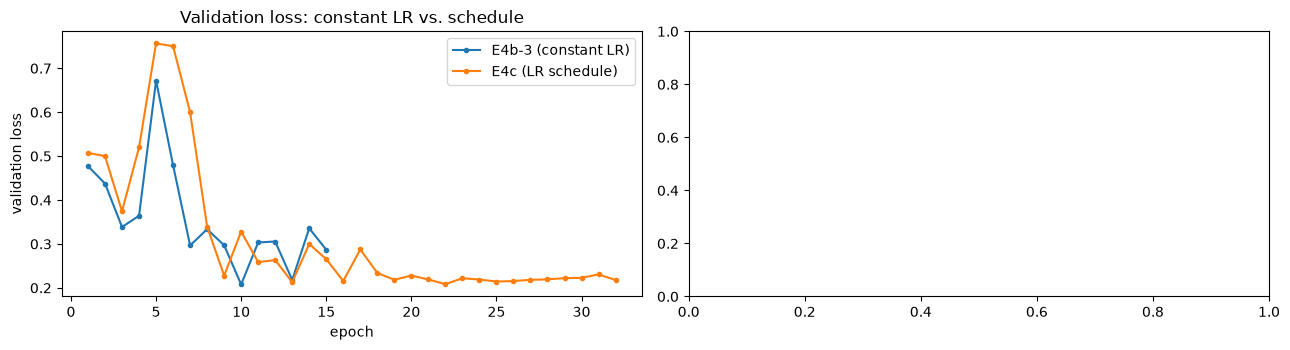

In [24]:
lr_hist = run_e4c.history()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for label, run in [("E4b-3 (constant LR)", sweep_runs["reg_d04_l2_0"][0]), ("E4c (LR schedule)", run_e4c)]:
    ax[0].plot(range(1, len(run.history()) + 1), run.history()["val_loss"], marker="o", ms=3, label=label)
ax[0].set(xlabel="epoch", ylabel="validation loss", title="Validation loss: constant LR vs. schedule"); ax[0].legend()
if "learning_rate" in lr_hist:
    ax[1].step(range(1, len(lr_hist) + 1), lr_hist["learning_rate"], where="post")
    ax[1].set(xlabel="epoch", ylabel="learning rate", yscale="log", title="E4c learning rate (halved on plateau)")
plt.tight_layout(); plt.show()

**Analysis: E4c (learning-rate schedule).** **Hypothesis confirmed.**

| Run | Train acc | Val acc | Gap | Val F1 | Val AUC |
|---|---|---|---|---|---|
| E3 (no regularization) | 99.9% | 90.8% | 9.1 | 0.831 | 0.960 |
| E4 (defaults) | 89.2% | 89.3% | ≈0 | 0.808 | 0.952 |
| E4b-3 (dropout 0.4, no L2) | 91.9% | 91.5% | 0.4 | 0.850 | 0.969 |
| **E4c (+ LR schedule)** | **93.4%** | **91.6%** | 1.8 | **0.861** | **0.978** |

* **The instability is gone.** In the first 7 epochs (learning rate 0.001 → 0.0005), validation loss jumped
  between 0.37 and 0.76. After the successive halvings, it stays between **0.21 and 0.23**. The learning rate was
  halved 5 times (0.001 → 0.00003): large steps at the start to learn quickly, then small steps to settle into
  the minimum instead of bouncing around it.
* Because training is stable, it can **run longer** (best epoch 22, stopped at 32, against best epoch 10 for
  E4b-3). Training accuracy rises to 93.4%, so **bias goes down**, while the gap stays small (1.8 points vs. 9.1
  in E3).
* **Best CNN trained from scratch:** F1 0.861, AUC 0.978.
* **Verdict: improvement.** The full regularization story is now: E3 overfits → E4 over-constrains → E4b finds
  that L2 was the culprit and dropout stabilizes → E4c fixes the optimization. Even so, the best from-scratch CNN
  (0.861) stays far below transfer learning (E6: 0.963), so **the limit is the knowledge contained in 25,000
  images, not the regularization.**

In [25]:
run_e4c.annotate("improvement", "LR halved on plateau (5x) + patience 10: val loss stabilised (0.21-0.23 vs 0.37-0.76), best epoch 22, F1 0.861 / AUC 0.978 = best from-scratch CNN; still far below transfer learning (0.963)")

### E5: transfer learning (frozen MobileNetV2)

**Hypothesis.** Telling a photo from a realistic painting depends on subtle cues: sensor noise, depth of field,
optical blur, natural textures versus brush strokes. With about 7,000 photos, a CNN trained from scratch
struggles to learn them. **MobileNetV2 pre-trained on ImageNet** (1.4 M natural photos) has already learned
those cues. We **freeze** it, use it as a feature extractor (1,280 features per image), and train only a sigmoid
classifier on top: 1,281 trainable parameters, so overfitting is very unlikely.

MobileNetV2 is a good fit here: it's light (2.3 M parameters), fast, and designed for limited hardware, which
suits both our 2 GB GPU and production use at TouNum.

[05_mobilenetv2_frozen] already trained: reusing saved results (RETRAIN=False)


**05_mobilenetv2_frozen**: 2,259,265 parameters, 13 epochs (early stopping, best epoch 9)

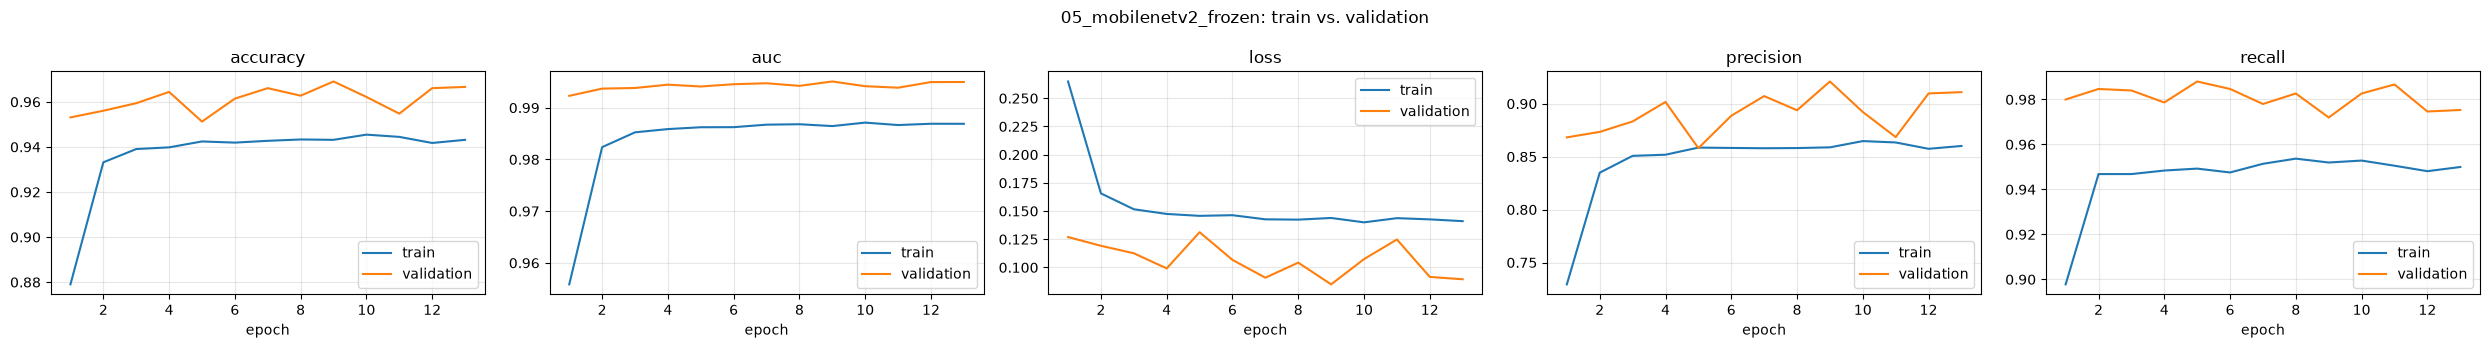

,accuracy,precision,recall,f1,roc_auc
train,0.976,0.939,0.977,0.958,0.997
val,0.969,0.921,0.972,0.946,0.995


,n,accuracy,predicted_photo
category,,,
Painting,1499,93.3%,6.7%
Schematics,685,96.5%,3.5%
Photo,1499,97.2%,97.2%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [26]:
run_e5, p_e5 = experiment(
    "mobilenetv2_frozen", "ImageNet features (frozen MobileNetV2) separate photos from paintings better than a CNN from scratch",
    builder="mobilenet_frozen", epochs=15, lr=1e-3, batch_size=64, early_stopping=True, patience=4,
    backbone="MobileNetV2/imagenet", trainable_layers="head only")

def transfer_mobilenet(img_size: int = 160, dropout: float = 0.3, trainable: bool = False, grayscale: float = 0.0):
    """E5/E6: MobileNetV2 pre-trained on ImageNet (1.4M natural photos) as a frozen feature extractor.
    Its features already encode 'natural image statistics' that separate photos from paintings.
    Returns (model, base) so the base can be partially unfrozen for fine-tuning."""
    base = keras.applications.MobileNetV2(input_shape=(img_size, img_size, 3), include_top=False,
                                          weights="imagenet")
    base.trainable = trainable
    inp = keras.Input((img_size, img_size, 3), name="image")
    x = augmentation(grayscale=grayscale)(inp)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)  # MobileNetV2 expects [-1, 1]
    x = base(x, training=False)  # keep BatchNorm in inference mode, even when fine-tuning
    x = layers.GlobalAveragePooling2D()(x)
    return keras.Model(inp, _head(x, dropout), name="mobilenetv2_transfer"), base



/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 6 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


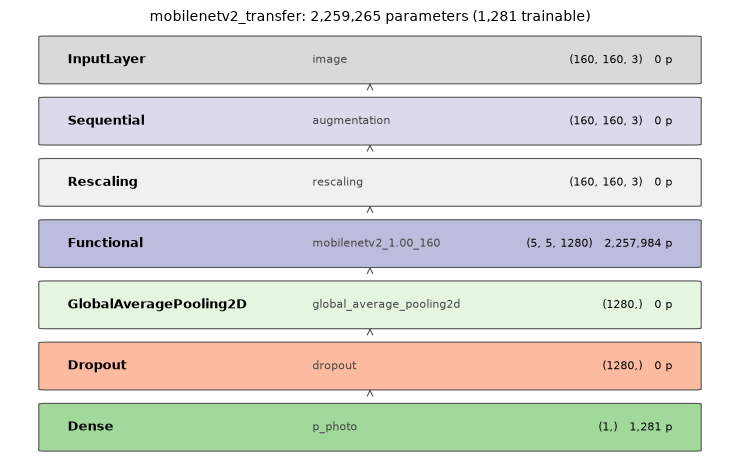

In [27]:
show_architecture(run_e5, M.transfer_mobilenet)

**Analysis: E5 (frozen MobileNetV2).** Big jump: validation accuracy **96.9%**, F1 **0.946**, AUC **0.995**
(vs. 0.831 / 0.960 for the best CNN trained from scratch). Training 97.6% vs. validation 96.9%: **low bias *and*
low variance**.

* Paintings are rejected 93.3% of the time (vs. 87% for E3/E4), and photo recall rises to 97.2%.
* Only **1,281 weights** are trained, a single neuron on top of 1,280 ImageNet features, so overfitting isn't
  possible. Early stopping kept epoch 9 of 13.
* Why it works: the ImageNet features already encode the statistics of natural photographs (sensor noise,
  optical blur, real textures) that separate a photo from a painting. Learning them from scratch would need far
  more than our 7,000 photos.
* **Verdict: improvement.** Lesson: the remaining errors are mostly realistic paintings. Adapting the top of the
  network to our task should help → fine-tuning (E6).

In [28]:
run_e5.annotate("improvement", "Transfer learning: F1 0.83 -> 0.946, AUC 0.995 with only 1,281 trained weights; low bias and low variance. Remaining errors: realistic paintings -> fine-tune the top layers")

### E6: fine-tuning MobileNetV2

**Hypothesis.** We now **unfreeze the last 40 layers** of MobileNetV2, which hold the most task-specific
features, and retrain them with a **learning rate 100× smaller** (1e-5), starting from E5's weights. They can
adapt to photo-vs-painting without destroying what ImageNet taught them. The early layers (generic edges and
colours) and the BatchNorm statistics stay frozen.

[06_mobilenetv2_finetuned] already trained: reusing saved results (RETRAIN=False)


**06_mobilenetv2_finetuned**: 2,259,265 parameters, 7 epochs (early stopping, best epoch 3)

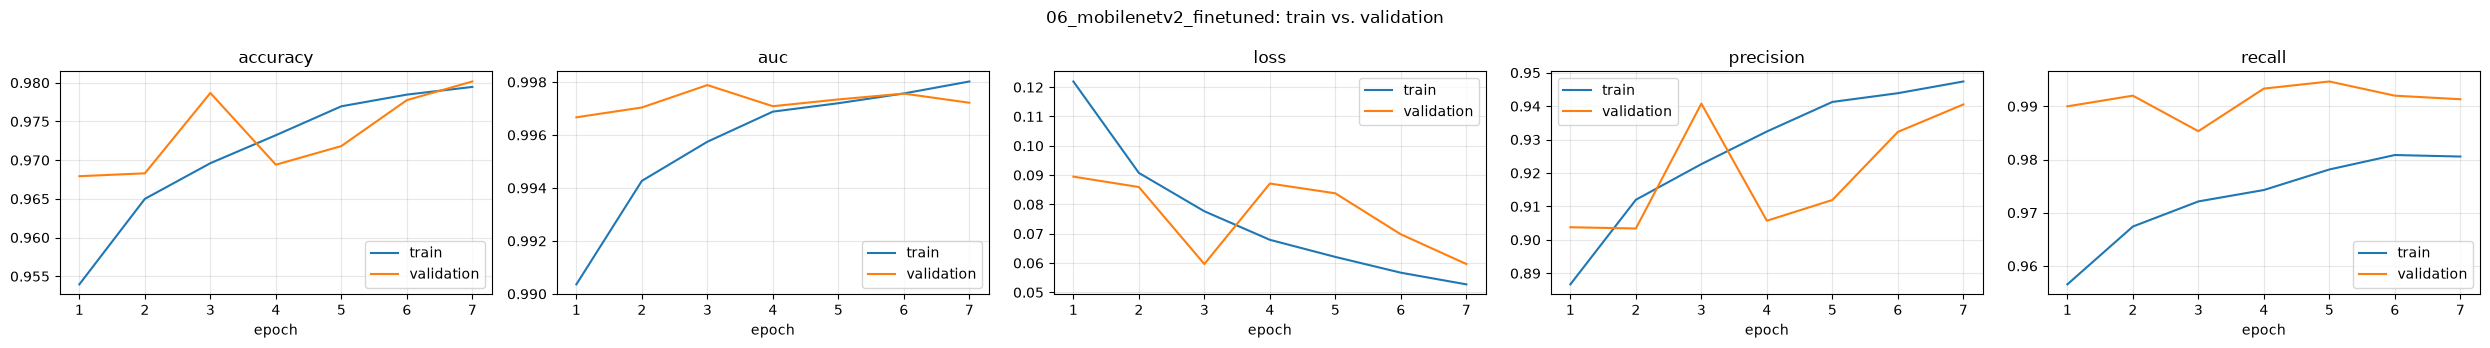

,accuracy,precision,recall,f1,roc_auc
train,0.983,0.953,0.988,0.970,0.999
val,0.979,0.941,0.985,0.963,0.998


,n,accuracy,predicted_photo
category,,,
Painting,1499,95.5%,4.5%
Schematics,685,96.2%,3.8%
Photo,1499,98.5%,98.5%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [29]:
run_e6, p_e6 = experiment(
    "mobilenetv2_finetuned", "Fine-tuning the top 40 MobileNetV2 layers at a low learning rate improves on E5",
    builder="mobilenet_finetune", builder_kwargs=dict(from_model=str(run_e5.dir / "model.keras"), n_layers=40),
    epochs=15, lr=1e-5, batch_size=32, early_stopping=True, patience=4,
    backbone="MobileNetV2/imagenet", trainable_layers="last 40 (BatchNorm frozen)", init="E5 weights")

In [30]:
print(inspect.getsource(M.unfreeze_top))

def unfreeze_top(base: keras.Model, n_layers: int = 40):
    """Fine-tuning: unfreeze only the last n layers (high-level, task-specific features);
    the first layers (generic edges/colours) stay frozen. BatchNorm layers stay frozen."""
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False



**Analysis: E6 (fine-tuned MobileNetV2).** Best model: validation accuracy **97.9%**, F1 **0.963**, AUC **0.998**,
training 98.3% (gap 0.4 point). Paintings are rejected **95.5%** of the time and photo recall reaches **98.5%**;
Sketches and Text are at 100%.

* Early stopping kept **epoch 3**: with a learning rate of 1e-5, a few epochs are enough to adapt the last 40
  layers. Training longer starts to overfit, because the model now has about 1.66 M trainable weights instead of 1,281.
* **Verdict: best**, selected for the final test (section 7).

In [31]:
run_e6.annotate("best", "Fine-tuning the last 40 layers at lr 1e-5: F1 0.963, AUC 0.998, gap 0.4 pt. Best epoch 3: low LR + early stopping prevent destroying ImageNet features")

## 7. Comparison and final evaluation

### 7.1 Experiments side by side (validation)

,params,train acc,val acc,gap,val F1,val AUC
E1 MLP,"6,357,761",0.851,0.797,0.054,0.697,0.891
E2 CNN easy-only,"6,942,529",0.997,0.753,0.243,0.688,0.872
E3 CNN no-reg,"6,942,529",0.999,0.908,0.091,0.831,0.960
E4 CNN regularized,"1,175,393",0.892,0.893,-0.001,0.808,0.952
"E4b d=0.2, L2=1e-05","1,175,393",0.868,0.862,0.006,0.776,0.937
"E4b d=0.0, L2=1e-05","1,175,393",0.840,0.840,0.000,0.736,0.915
"E4b d=0.4, L2=0","1,175,393",0.919,0.915,0.004,0.850,0.969
"E4c d=0.4, L2=0 + LR schedule","1,175,393",0.934,0.916,0.018,0.861,0.978
E5 MobileNetV2 frozen,"2,259,265",0.976,0.969,0.007,0.946,0.995
E6 MobileNetV2 fine-tuned,"2,259,265",0.983,0.979,0.004,0.963,0.998


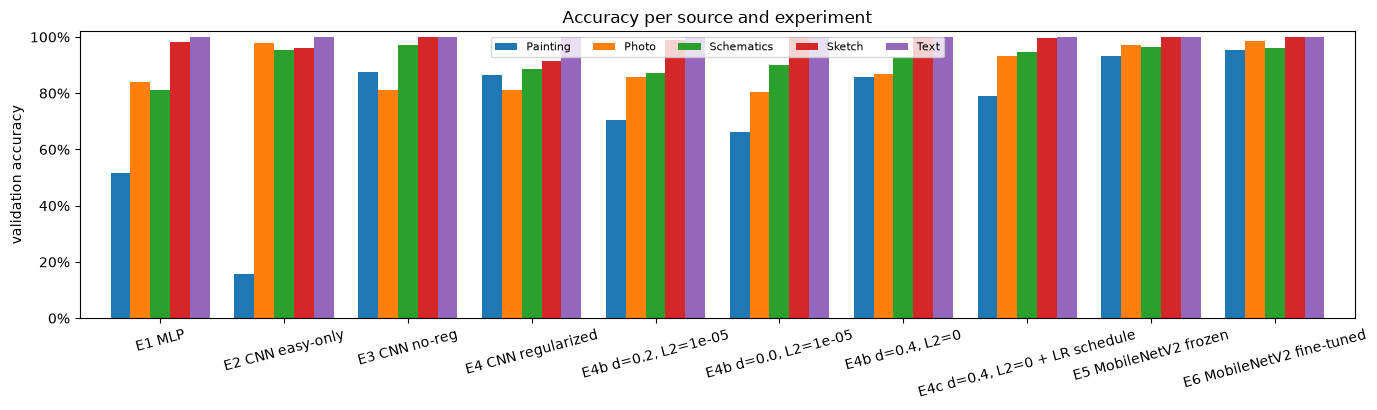

In [32]:
runs = {"E1 MLP": (run_e1, p_e1), "E2 CNN easy-only": (run_e2, p_e2), "E3 CNN no-reg": (run_e3, p_e3),
        "E4 CNN regularized": (run_e4, p_e4),
        **{f"E4b d={d}, L2={l2:g}": sweep_runs[n] for n, d, l2 in SWEEP},
        "E4c d=0.4, L2=0 + LR schedule": (run_e4c, p_e4c),
        "E5 MobileNetV2 frozen": (run_e5, p_e5),
        "E6 MobileNetV2 fine-tuned": (run_e6, p_e6)}
rows = {}
for label, (run, probs) in runs.items():
    ev = run.summary()["eval_metrics"]
    rows[label] = {"params": run.summary()["params"], "train acc": ev["train_accuracy"], "val acc": ev["val_accuracy"],
                   "gap": ev["train_accuracy"] - ev["val_accuracy"], "val F1": ev["val_f1"], "val AUC": ev["val_roc_auc"]}
comparison = pd.DataFrame(rows).T
display(comparison.style.format({"params": "{:,.0f}", **{c: "{:.3f}" for c in comparison.columns[1:]}})
        .highlight_max(subset=["val F1", "val AUC"], color="#c7e9c0"))

per_source = pd.DataFrame({label: per_category_report(val_df, probs)["accuracy"] for label, (_, probs) in runs.items()})
fig, ax = plt.subplots(figsize=(14, 4.2))
per_source.T.plot.bar(ax=ax, width=0.8)
ax.set_ylim(0, 1.02); ax.set_ylabel("validation accuracy"); ax.set_title("Accuracy per source and experiment")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); plt.xticks(rotation=15); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.savefig(REPORTS_DIR / "figures" / "d1_per_source.png", dpi=110); plt.show()

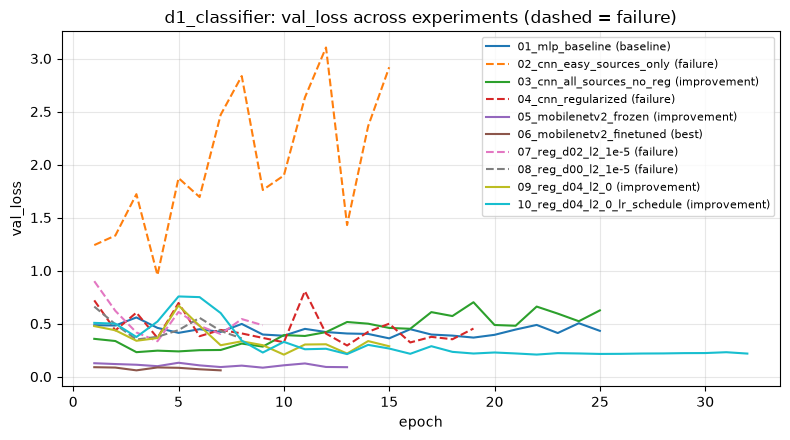

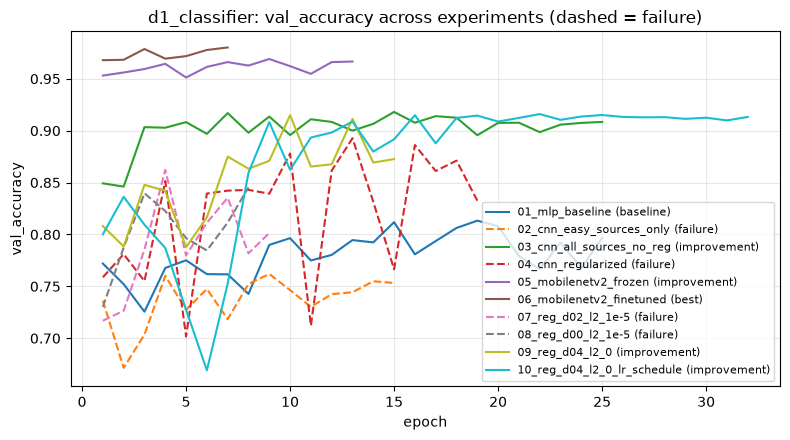

In [33]:
plot_runs(DELIVERABLE, "val_loss", save_to=REPORTS_DIR / "figures" / "d1_val_loss.png")
plot_runs(DELIVERABLE, "val_accuracy", save_to=REPORTS_DIR / "figures" / "d1_val_accuracy.png")

### 7.2 Choosing the decision threshold

The model outputs a probability. The default threshold of 0.5 isn't necessarily the right one for TouNum. We choose
it **on validation** (never on test) to maximize F1, and show the precision/recall trade-off so TouNum can adjust it
for its own priority: miss fewer photos, or let through fewer non-photos.

/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 32 variables whereas the saved optimizer has 36 variables. 
  saveable.load_own_variables(store)


selected model: E6 MobileNetV2 fine-tuned


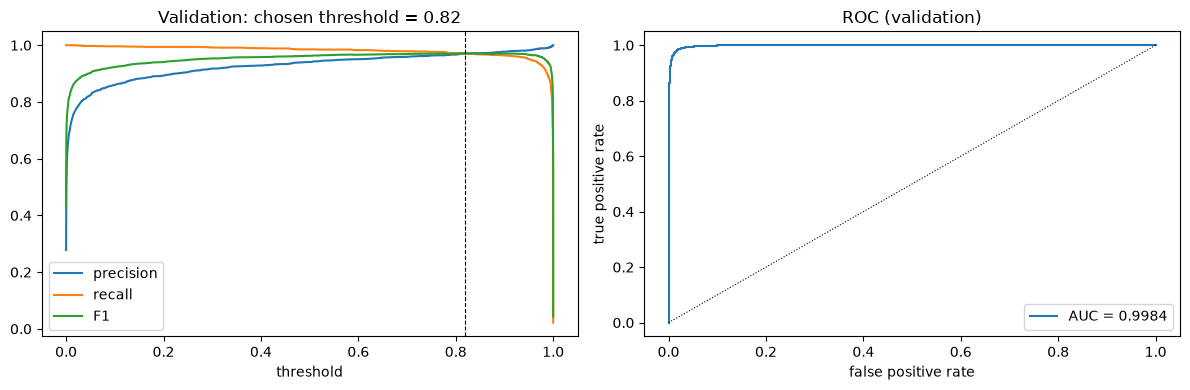

In [34]:
from sklearn.metrics import precision_recall_curve, roc_curve, auc

best_label = comparison["val F1"].idxmax()
best_run, best_val_probs = runs[best_label]
best_model = best_run.load_model()
print("selected model:", best_label)

prec, rec, thr = precision_recall_curve(val_df["label"], best_val_probs)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
THRESHOLD = float(thr[np.argmax(f1[:-1])])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(thr, prec[:-1], label="precision"); ax[0].plot(thr, rec[:-1], label="recall"); ax[0].plot(thr, f1[:-1], label="F1")
ax[0].axvline(THRESHOLD, ls="--", c="k", lw=0.8); ax[0].set(xlabel="threshold", title=f"Validation: chosen threshold = {THRESHOLD:.2f}"); ax[0].legend()
fpr, tpr, _ = roc_curve(val_df["label"], best_val_probs)
ax[1].plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.4f}"); ax[1].plot([0, 1], [0, 1], "k:", lw=0.8)
ax[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (validation)"); ax[1].legend()
plt.tight_layout(); plt.show()

### 7.3 Final evaluation on the test set (used only once)

,accuracy,precision,recall,f1,roc_auc
threshold 0.5,0.9750,0.9322,0.9813,0.9561,0.9972
threshold 0.82,0.9789,0.9620,0.9620,0.9620,0.9972


,n,accuracy,predicted_photo
category,,,
Photo,1499,96.20%,96.20%
Painting,1499,97.33%,2.67%
Schematics,685,97.52%,2.48%
Sketch,211,100.00%,0.00%
Text,1500,100.00%,0.00%


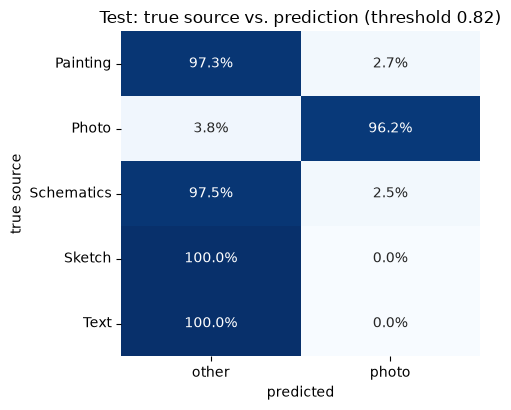

In [35]:
test_ds = make_dataset(test_df, IMG, VAL_BS, cache=CACHE / f"test_{IMG}")
test_probs = predict(best_model, test_ds)
final = pd.DataFrame({"threshold 0.5": binary_metrics(test_df["label"], test_probs, 0.5),
                      f"threshold {THRESHOLD:.2f}": binary_metrics(test_df["label"], test_probs, THRESHOLD)}).T
display(final.style.format("{:.4f}").set_caption(f"Test set ({len(test_df):,} images): {best_label}"))
display(per_category_report(test_df, test_probs, THRESHOLD).style.format({"accuracy": "{:.2%}", "predicted_photo": "{:.2%}"}))
plot_confusion(test_df, test_probs, THRESHOLD, title=f"Test: true source vs. prediction (threshold {THRESHOLD:.2f})")

**The most confident mistakes on the test set:**

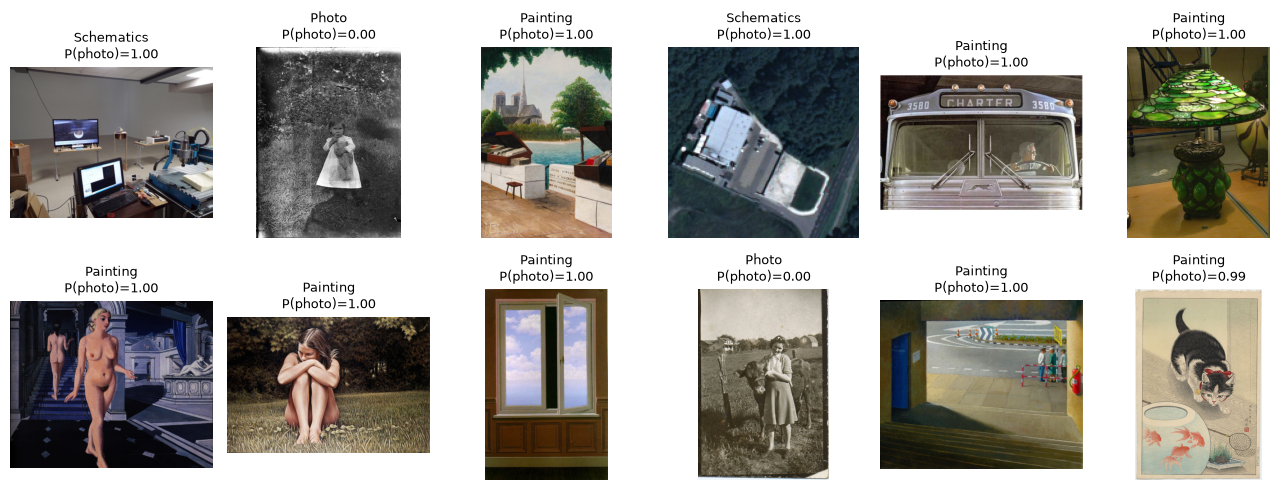

In [36]:
plot_errors(test_df, test_probs, THRESHOLD, n=12)

## 8. Robustness: has the model learned a shortcut?

The audit (section 3) showed that the non-photo sources contain many grayscale images while photos are in colour.
**If the model has learned "grayscale ⇒ not a photo", it will reject every black-and-white photo**, which is
exactly what old archives contain. We check this by converting the test photos to grayscale and comparing how many
are still recognized.

In [37]:
@tf.autograph.experimental.do_not_convert
def to_grayscale(x, y):
    gray = tf.image.rgb_to_grayscale(tf.cast(x, tf.float32))
    return tf.cast(tf.image.grayscale_to_rgb(gray), tf.uint8), y

test_photos = test_df[test_df["label"] == 1]
p_color = predict(best_model, make_dataset(test_photos, IMG, VAL_BS))
p_gray = predict(best_model, make_dataset(test_photos, IMG, VAL_BS).map(to_grayscale))
stress = pd.DataFrame({f"threshold {t:.2f}": {"photo recall (colour)": (p_color >= t).mean(),
                                              "photo recall (grayscale)": (p_gray >= t).mean()}
                       for t in (0.5, THRESHOLD)}).T
stress["drop"] = stress.iloc[:, 0] - stress.iloc[:, 1]
display(stress.style.format("{:.1%}").set_caption(f"{best_label}: the same {len(test_photos)} test photos, colour vs. grayscale"))

,photo recall (colour),photo recall (grayscale),drop
threshold 0.50,98.1%,95.8%,2.3%
threshold 0.82,96.2%,91.9%,4.3%


**Analysis: robustness and error analysis.**

* **Test results (5,394 images never used before):** accuracy **97.9%**, precision **96.2%**, recall **96.2%**,
  F1 **0.962**, AUC **0.997**, very close to validation (F1 0.963), so model selection didn't overfit the
  validation set. Errors: 57 photos missed, 57 non-photos accepted (40 paintings, 17 schematics). **Text and
  Sketches: 0 errors.**
* **Threshold:** at 0.5, recall is 98.1% and precision 93.2%. At the threshold chosen on validation (0.82), both
  are 96.2%. **This is a business choice for TouNum:** if missing a photo costs more than captioning a non-photo,
  use a lower threshold.
* **Grayscale stress test:** photo recall drops from **96.2% to 91.9%** (98.1% → 95.8% at 0.5). The model has
  **partly** learned the colour shortcut identified in the audit. It isn't a collapse, but it's a real risk.
* **The error gallery confirms it.** The photos the model misses with the most confidence (P(photo) ≈ 0) are
  **old, damaged, sepia or black-and-white prints**, exactly what heritage archives contain. Our training photos
  are modern colour pictures, so the model has rarely seen this kind of photo.
* **Many "errors" are label errors.** Several images in the *Schematics* archive are real photos (a laboratory,
  an aerial view, a product shot, a microscope image), and several *Paintings* are photos too (a bus driver,
  Tiffany lamps). **The model is right and the folder is wrong.** Archive folders are a *noisy* label source, so
  the true performance is somewhat higher than measured.
* Genuine hard cases: hyper-realistic paintings (Magritte, illustrated realistic scenes) and scientific figures
  with smooth colour gradients (heatmaps), which look like photos at 160×160.

In [38]:
best_run.annotate("best", "Test F1 0.962 / AUC 0.997. Weakness: grayscale photos (recall 96.2 -> 91.9%), old sepia prints missed. Some errors are label noise in the archives")

## 9. Bias / variance analysis and training journal

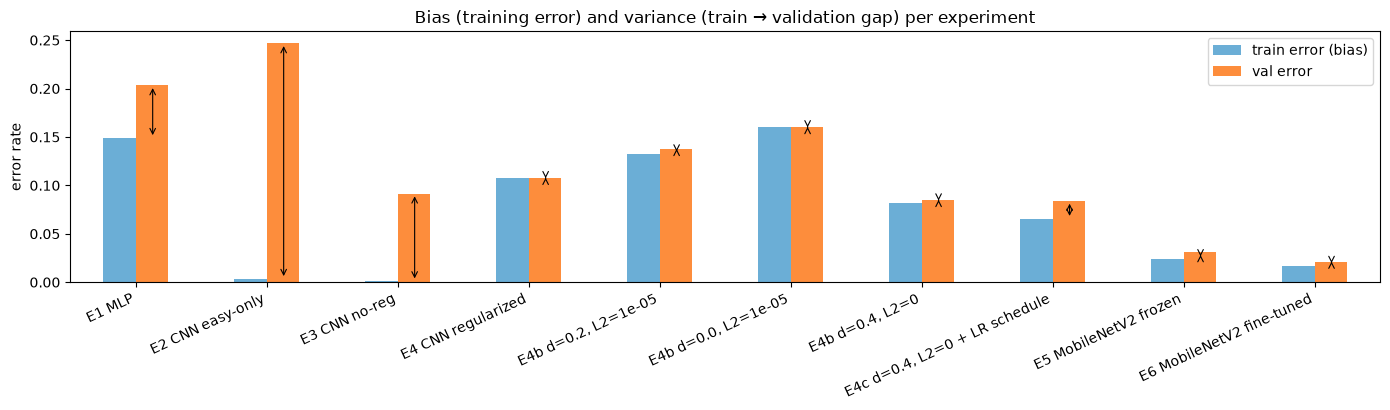

In [39]:
bv = comparison[["train acc", "val acc", "gap"]].copy()
bv["train error (bias)"] = 1 - bv["train acc"]
bv["val error"] = 1 - bv["val acc"]
fig, ax = plt.subplots(figsize=(14, 4.2))
bv[["train error (bias)", "val error"]].plot.bar(ax=ax, color=["#6baed6", "#fd8d3c"])
for i, (tr, va) in enumerate(zip(bv["train error (bias)"], bv["val error"])):
    ax.annotate("", xy=(i + 0.13, va), xytext=(i + 0.13, tr), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax.set_ylabel("error rate"); ax.set_title("Bias (training error) and variance (train → validation gap) per experiment")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.savefig(REPORTS_DIR / "figures" / "d1_bias_variance.png", dpi=110); plt.show()

**How to read the chart:** the **blue bar (training error)** measures **bias**; the **distance between the bars**
measures **variance**.

| Experiment | Diagnosis | What fixed it |
|---|---|---|
| E1 MLP | **high bias** (train error 15%) | a model that understands images (CNN) |
| E2 CNN easy-only | gap caused by a **data mismatch** (sources unseen in training) | training on every source |
| E3 CNN no reg. | **high variance** (train error ~0%, gap 9 pts) | regularization |
| E4 CNN regularized | variance fixed, **bias up** (train error 11%) | tuning the regularization (E4b) |
| E4b / E4c tuned CNN | small gap, bias down (train error 6.6%), F1 0.861 | removing L2, keeping dropout, LR schedule; then more prior knowledge |
| E5 / E6 transfer | **low bias and low variance** (gap < 1 pt) | knowledge from 1.4 M ImageNet images |

**Conclusion.** Regularization moves us *along* the bias/variance trade-off: less variance costs more bias.
**Transfer learning moves the trade-off itself**, because the model's knowledge no longer comes only from our
25,000 images. Then early stopping and a tiny learning rate keep fine-tuning on the low-variance side.

**Engineering lessons (failures outside the model).** These are part of the journal too:

1. **XLA crash** ("Autotuning failed... No valid config found"): Keras 3's compiler needs scratch GPU memory our
   2 GB GPU doesn't have. → `jit_compile=False`.
2. **GPU out-of-memory at the 2nd experiment:** TensorFlow can't release GPU memory between models in one
   process (fragmentation; the alternative allocator isn't supported on this virtual GPU). → **one process per
   training run** (`python -m leyenda.train`); the notebook stays on the CPU.
3. **Stale cache, caught by a dry run:** a cache named only `val_160` was reused with *different* images (112
   labels vs. 128 predictions). Had the sizes matched, the scores would have been silently wrong. → cache name
   keyed on a hash of the exact image list. Lesson: always run a short end-to-end test before a long run.

In [40]:
display(Markdown(training_journal(DELIVERABLE)))

# Training journal: d1_classifier

## 01_mlp_baseline: **BASELINE**
- **Hypothesis:** A fully-connected network on flattened 64x64 pixels can separate photos from other images
- **Config:** `{"builder": "mlp", "builder_kwargs": {}, "epochs": 25, "lr": 0.001, "batch_size": 64, "img_size": 160, "train_sources": null, "early_stopping": false, "patience": 6}`
- **Evaluation:** val_accuracy=0.7966, val_precision=0.5949, val_recall=0.8406, val_f1=0.6967, val_roc_auc=0.8906, train_accuracy=0.8510, train_precision=0.6670, train_recall=0.9261, train_f1=0.7754, train_roc_auc=0.9467
- **Train/val loss gap:** 0.1279 (best val epoch 15/25)
- **Lesson / next step:** High bias: an MLP on flattened pixels cannot fit the task (train 85%). Paintings rejected only 52% of the time -> use a CNN

## 02_cnn_easy_sources_only: **FAILURE**
- **Hypothesis:** A simple CNN trained on photo vs text/schematics generalises to paintings and sketches
- **Config:** `{"builder": "simple_cnn", "builder_kwargs": {}, "epochs": 15, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": ["Photo", "Text", "Schematics"], "early_stopping": false, "patience": 6}`
- **Evaluation:** val_accuracy=0.7532, val_precision=0.5303, val_recall=0.9800, val_f1=0.6882, val_roc_auc=0.8724, train_accuracy=0.9966, train_precision=0.9952, train_recall=0.9964, train_f1=0.9958, train_roc_auc=0.9999
- **Train/val loss gap:** 2.8996 (best val epoch 4/15)
- **Lesson / next step:** Trained without paintings/sketches, it calls 84% of paintings photos: a model only learns distinctions present in its training data -> train on all sources

## 03_cnn_all_sources_no_reg: **IMPROVEMENT**
- **Hypothesis:** The same CNN trained on all sources learns to reject paintings and sketches
- **Config:** `{"builder": "simple_cnn", "builder_kwargs": {}, "epochs": 25, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": false, "patience": 6}`
- **Evaluation:** val_accuracy=0.9084, val_precision=0.8531, val_recall=0.8099, val_f1=0.8309, val_roc_auc=0.9605, train_accuracy=0.9990, train_precision=0.9988, train_recall=0.9976, train_f1=0.9982, train_roc_auc=1.0000
- **Train/val loss gap:** 0.6081 (best val epoch 3/25)
- **Lesson / next step:** Adding hard sources: F1 0.69 -> 0.83, but train 99.9% vs val 90.8%: high variance (val loss rises while train loss falls) -> regularise

## 04_cnn_regularized: **FAILURE**
- **Hypothesis:** Augmentation + BatchNorm + L2 + GAP + dropout + early stopping close E3's generalisation gap
- **Config:** `{"builder": "regularized_cnn", "builder_kwargs": {"l2": 0.0001, "dropout": 0.4}, "epochs": 40, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 6, "augmentation": "flip/rot/zoom/translate"}`
- **Evaluation:** val_accuracy=0.8927, val_precision=0.8038, val_recall=0.8119, val_f1=0.8078, val_roc_auc=0.9519, train_accuracy=0.8921, train_precision=0.7918, train_recall=0.8296, train_f1=0.8102, train_roc_auc=0.9514
- **Train/val loss gap:** 0.1763 (best val epoch 13/19)
- **Lesson / next step:** Gap closed (train 89.2 / val 89.3) but F1 0.808 < E3: over-regularised, bias went up (trade-off). Defaults are not tuned values -> E4b sweep; from-scratch CNN capped ~90% -> transfer learning

## 05_mobilenetv2_frozen: **IMPROVEMENT**
- **Hypothesis:** ImageNet features (frozen MobileNetV2) separate photos from paintings better than a CNN from scratch
- **Config:** `{"builder": "mobilenet_frozen", "builder_kwargs": {}, "epochs": 15, "lr": 0.001, "batch_size": 64, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 4, "backbone": "MobileNetV2/imagenet", "trainable_layers": "head only"}`
- **Evaluation:** val_accuracy=0.9690, val_precision=0.9210, val_recall=0.9720, val_f1=0.9458, val_roc_auc=0.9951, train_accuracy=0.9762, train_precision=0.9393, train_recall=0.9774, train_f1=0.9579, train_roc_auc=0.9973
- **Train/val loss gap:** -0.0515 (best val epoch 9/13)
- **Lesson / next step:** Transfer learning: F1 0.83 -> 0.946, AUC 0.995 with only 1,281 trained weights; low bias and low variance. Remaining errors: realistic paintings -> fine-tune the top layers

## 06_mobilenetv2_finetuned: **BEST**
- **Hypothesis:** Fine-tuning the top 40 MobileNetV2 layers at a low learning rate improves on E5
- **Config:** `{"builder": "mobilenet_finetune", "builder_kwargs": {"from_model": "/home/utilisateur/Bureau/DataScienceA5/runs/d1_classifier/05_mobilenetv2_frozen/model.keras", "n_layers": 40}, "epochs": 15, "lr": 1e-05, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 4, "backbone": "MobileNetV2/imagenet", "trainable_layers": "last 40 (BatchNorm frozen)", "init": "E5 weights"}`
- **Evaluation:** val_accuracy=0.9787, val_precision=0.9408, val_recall=0.9853, val_f1=0.9625, val_roc_auc=0.9984, train_accuracy=0.9831, train_precision=0.9529, train_recall=0.9881, train_f1=0.9702, train_roc_auc=0.9991
- **Train/val loss gap:** 0.0069 (best val epoch 3/7)
- **Lesson / next step:** Test F1 0.962 / AUC 0.997. Weakness: grayscale photos (recall 96.2 -> 91.9%), old sepia prints missed. Some errors are label noise in the archives

## 07_reg_d02_l2_1e-5: **FAILURE**
- **Hypothesis:** Lighter regularisation (dropout 0.2, L2 1e-05) than E4 lowers bias while keeping the gap small
- **Config:** `{"builder": "regularized_cnn", "epochs": 30, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 5, "augmentation": "flip/rot/zoom/translate", "builder_kwargs": {"dropout": 0.2, "l2": 1e-05}}`
- **Evaluation:** val_accuracy=0.8623, val_precision=0.7079, val_recall=0.8586, val_f1=0.7760, val_roc_auc=0.9368, train_accuracy=0.8679, train_precision=0.7099, train_recall=0.8868, train_f1=0.7886, train_roc_auc=0.9393
- **Train/val loss gap:** 0.2057 (best val epoch 4/9)
- **Lesson / next step:** Lighter reg. did NOT lower bias: early stopping fired at epoch 9 on oscillating val loss (best ep 4), F1 0.776

## 08_reg_d00_l2_1e-5: **FAILURE**
- **Hypothesis:** Lighter regularisation (dropout 0.0, L2 1e-05) than E4 lowers bias while keeping the gap small
- **Config:** `{"builder": "regularized_cnn", "epochs": 30, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 5, "augmentation": "flip/rot/zoom/translate", "builder_kwargs": {"dropout": 0.0, "l2": 1e-05}}`
- **Evaluation:** val_accuracy=0.8396, val_precision=0.6779, val_recall=0.8059, val_f1=0.7364, val_roc_auc=0.9153, train_accuracy=0.8401, train_precision=0.6738, train_recall=0.8224, train_f1=0.7407, train_roc_auc=0.9177
- **Train/val loss gap:** 0.0664 (best val epoch 3/8)
- **Lesson / next step:** No dropout: even earlier stop (epoch 8), F1 0.736 -> dropout also stabilises training

## 09_reg_d04_l2_0: **IMPROVEMENT**
- **Hypothesis:** Lighter regularisation (dropout 0.4, L2 0.0) than E4 lowers bias while keeping the gap small
- **Config:** `{"builder": "regularized_cnn", "epochs": 30, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 5, "augmentation": "flip/rot/zoom/translate", "builder_kwargs": {"dropout": 0.4, "l2": 0.0}}`
- **Evaluation:** val_accuracy=0.9149, val_precision=0.8316, val_recall=0.8699, val_f1=0.8503, val_roc_auc=0.9694, train_accuracy=0.9186, train_precision=0.8291, train_recall=0.8903, train_f1=0.8586, train_roc_auc=0.9719
- **Train/val loss gap:** 0.0753 (best val epoch 10/15)
- **Lesson / next step:** Dropout 0.4 without L2: best from-scratch CNN, F1 0.850 / AUC 0.969, gap 0.4 pt -> L2 was over-constraining. Val loss still oscillates -> LR schedule (E4c)

## 10_reg_d04_l2_0_lr_schedule: **IMPROVEMENT**
- **Hypothesis:** With E4b-3 regularisation, halving the LR on plateau and patience 10 stabilise training and lower bias further
- **Config:** `{"builder": "regularized_cnn", "builder_kwargs": {"dropout": 0.4, "l2": 0.0}, "epochs": 40, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 10, "reduce_lr": true, "augmentation": "flip/rot/zoom/translate"}`
- **Evaluation:** val_accuracy=0.9160, val_precision=0.7982, val_recall=0.9340, val_f1=0.8607, val_roc_auc=0.9776, train_accuracy=0.9345, train_precision=0.8294, train_recall=0.9619, train_f1=0.8907, train_roc_auc=0.9847
- **Train/val loss gap:** 0.0704 (best val epoch 22/32)
- **Lesson / next step:** LR halved on plateau (5x) + patience 10: val loss stabilised (0.21-0.23 vs 0.37-0.76), best epoch 22, F1 0.861 / AUC 0.978 = best from-scratch CNN; still far below transfer learning (0.963)


## 10. Ways to further improve the bias/variance trade-off

**Already applied in this notebook:** class weights (imbalance), data augmentation, Batch Normalization, L2 weight
decay, dropout, Global Average Pooling, early stopping (E4); tuning of dropout/L2 on validation (E4b); a
learning-rate schedule against unstable training (E4c); transfer
learning and fine-tuning with a 100× smaller learning rate and frozen BatchNorm (E5–E6); threshold chosen on
validation.

**Next steps, by expected impact for TouNum:**

| Improvement | Targets | Why |
|---|---|---|
| **Random-grayscale + sepia augmentation** (e.g. 20–30% of training photos) | bias on old photos | fixes the colour shortcut found in section 8, so B&W archives aren't rejected |
| **Add real old / B&W photos** to the Photo class (TouNum's own archives) | data mismatch | the training photos are modern colour images, unlike the target archives |
| **Clean the labels** of the archives (review high-confidence "errors") | noisy labels | several "Schematics/Paintings" are real photos; noisy labels cap accuracy and distort the evaluation |
| **Hard-example mining** on realistic paintings | remaining errors | over-sample the paintings the model gets wrong |
| Larger input (224 px) or stronger backbone (EfficientNet-B0, ConvNeXt-Tiny) | bias | finer detail (brush strokes, sensor noise); needs more GPU memory than 2 GB |
| More Sketch data (only 1,406 images) | variance on that class | already at 100% here, but a small class is a fragile estimate |
| k-fold cross-validation | reliability of the estimate | a confidence interval instead of a single split |
| Probability calibration + per-client threshold | business fit | lets TouNum set the photo-recall vs. precision trade-off per project |

# Part 2: complete dataset and optimization

After part 1, TouNum delivered the **complete archive**: the Schematics folder now has 10,000 images instead of
5,051 (+4,949), plus 1 painting missing from the first delivery, and one Windows system file (`desktop.ini`).

Part 1 told us **what works**: transfer learning (E5/E6) beats every CNN trained from scratch (F1 0.963 vs.
0.861 at best). It also told us **what's still wrong**: old black-and-white photos are rejected (photo recall
96.2% → 91.9% in grayscale), some archive labels are wrong, and realistic paintings remain hard. Part 2:

1. **Re-audits and re-splits** the complete dataset with the same code (`build_index`, `clean_index`, `split`).
   Nothing is chosen by hand.
2. Retrains **only transfer-learning models**, changing **one thing per experiment** (the lesson of the E4b
   sweep):

| Run | Change vs. previous | Question |
|---|---|---|
| V1 | E5 → E6 recipe on the new data | what does the extra data alone give? (new reference) |
| V2 | + **grayscale augmentation** (25% of training images) | does it remove the colour shortcut? |
| V3 | + **label smoothing** 0.05, fine-tune **60** layers, **LR schedule** | does a better fine-tuning recipe help? |
| V4 | V3 at **224 px** instead of 160 | do more pixels help with realistic paintings? |

> Why not compare with E6 directly? The new split is different, so some of the new test images were in E6's
> *training* set. Comparing on them would be data leakage. V1 retrains E6's recipe on the new split instead.

## 12. The complete dataset: audit, cleaning and new split

In [41]:
INDEX_V2 = DATA_DIR / "processed" / "index_v2.csv"
if INDEX_V2.exists():
    raw2 = pd.read_csv(INDEX_V2)
else:                       # same audit code as section 3, on the complete archive
    raw2 = build_index()
    raw2.to_csv(INDEX_V2, index=False)
raw2["new_in_v2"] = ~raw2["path"].isin(raw["path"])
display(raw2.groupby("category").agg(images=("path", "size"), new_images=("new_in_v2", "sum"),
                                      unreadable=("readable", lambda r: int((~r).sum()))))

new = raw2[raw2["new_in_v2"]]
print(f"new images: {len(new)} | smaller than 32 px: {int((new[['width', 'height']].min(axis=1) < 32).sum())}"
      f" | exact copies of an image from the first delivery: {int(new['md5'].isin(raw2.loc[~raw2['new_in_v2'], 'md5']).sum())}"
      f" | duplicated among themselves: {int(new['md5'].duplicated().sum())}")

clean2, removed2 = clean_index(raw2, min_side=32)
display(removed2.groupby(["reason", "category"]).size().rename("removed").to_frame())

SPLIT_V2 = "d1_split_v2.csv"
if (DATA_DIR / "processed" / SPLIT_V2).exists():
    data2 = pd.read_csv(DATA_DIR / "processed" / SPLIT_V2)
else:
    data2 = split(clean2, val=0.15, test=0.15, seed=42)
    data2.to_csv(DATA_DIR / "processed" / SPLIT_V2, index=False)
train2, val2, test2 = (data2[data2["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))
display(pd.crosstab(data2["category"], data2["split"], margins=True)[["train", "val", "test", "All"]])
print(f"photo share in train: {train2['label'].mean():.1%}")

,images,new_images,unreadable
category,,,
Painting,10000,1,0
Photo,9993,0,0
Schematics,10000,4949,0
Sketch,1406,0,0
Text,10000,0,0


new images: 4950 | smaller than 32 px: 327 | exact copies of an image from the first delivery: 337 | duplicated among themselves: 229


removed
reason                      category           
duplicate within category   Painting          4
                            Schematics      430
                            Text              1
not decodable by TensorFlow Painting          1
smaller than 32px           Schematics      662

split,train,val,test,All
category,,,,
Painting,6996,1499,1500,9995
Photo,6995,1499,1499,9993
Schematics,6236,1336,1336,8908
Sketch,984,211,211,1406
Text,6999,1500,1500,9999
All,28210,6045,6046,40301


photo share in train: 24.8%


**What the audit found, automatically.** The new Schematics contain the same kind of debris as the first
delivery: hundreds of fragments under 32 px and hundreds of exact duplicates (some identical to images we
already had). `clean_index` removes them with the same rules as in part 1, and `desktop.ini` is ignored because
the index only keeps image files.

**A trap caught by a failed run.** Our first part-2 training crashed at epoch 1 with a TensorFlow *decoding*
error. The cause: the single new painting (`painting_02662.jpg`) is actually a **BMP file with a `.jpg` name**.
PIL opens it, so the audit had marked it readable, but TensorFlow's decoder can't. **Fix in the code:** the audit
now also checks every file with **the same decoder the training uses** (`tf_decodable` column), and
`clean_index` removes those that fail ("not decodable by TensorFlow" in the table above). Lesson: validate data
with the tool that will consume it. After cleaning, Schematics nearly double, which is useful because heatmaps and
other diagrams with smooth colour gradients were among E6's remaining errors. Photos are now 24.8% of the training
set, and the class weights adjust automatically.

## 13. Transfer-learning experiments on the complete dataset

Each model is trained in two stages, like E5 → E6: (1) MobileNetV2 frozen, only the classifier is trained
(lr 1e-3); (2) the top layers are unfrozen and fine-tuned with a 100× smaller learning rate. Every run is tracked
in `runs/d1_classifier_v2/` and checkpointed after every epoch.

In [42]:
D2 = "d1_classifier_v2"
def v2(**kw):
    return experiment(deliverable=D2, split_file=SPLIT_V2, val=val2, **kw)

### V1: the E6 recipe on the complete dataset (new reference)
**Hypothesis.** With ~2,000 more clean Schematics, the same recipe as E5 → E6 reaches at least E6's level on
the new validation set.

[01_v1_frozen] already trained: reusing saved results (RETRAIN=False)


**01_v1_frozen**: 2,259,265 parameters, 12 epochs (early stopping, best epoch 8)

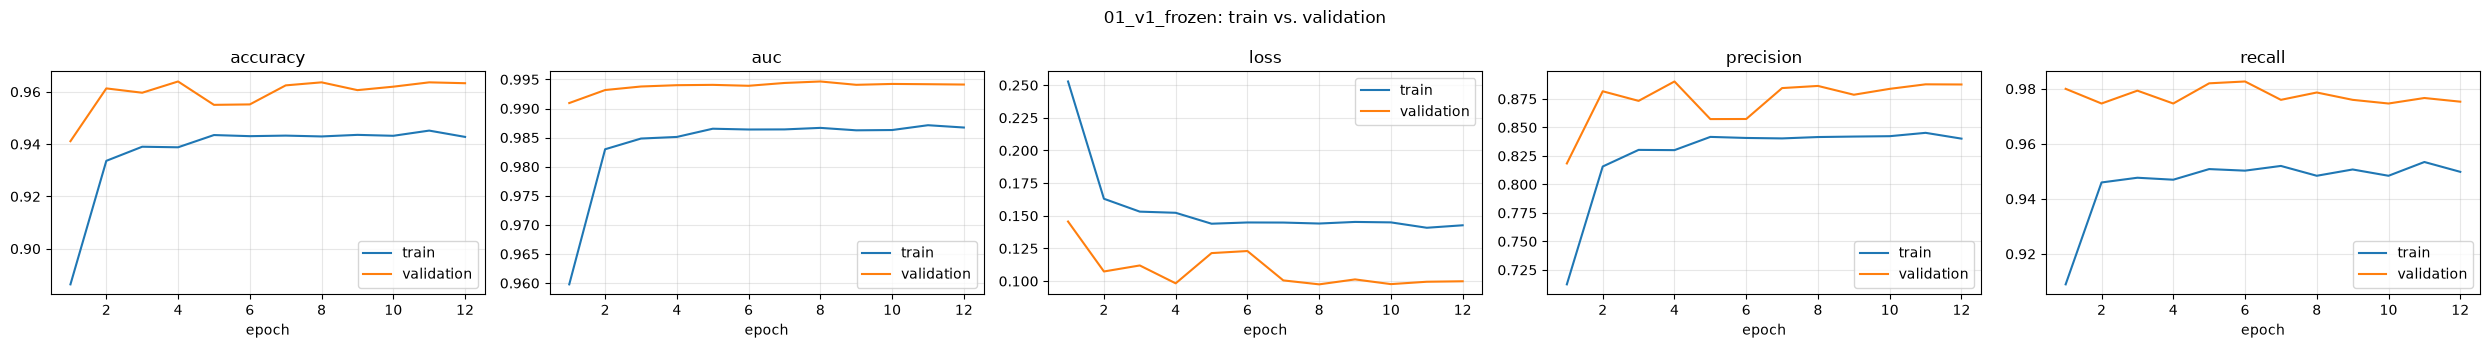

,accuracy,precision,recall,f1,roc_auc
train,0.968,0.898,0.985,0.939,0.996
val,0.964,0.886,0.979,0.930,0.995


,n,accuracy,predicted_photo
category,,,
Painting,1499,91.0%,9.0%
Schematics,1336,96.0%,4.0%
Photo,1499,97.9%,97.9%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


[02_v1_finetune40] already trained: reusing saved results (RETRAIN=False)


**02_v1_finetune40**: 2,259,265 parameters, 8 epochs (early stopping, best epoch 4)

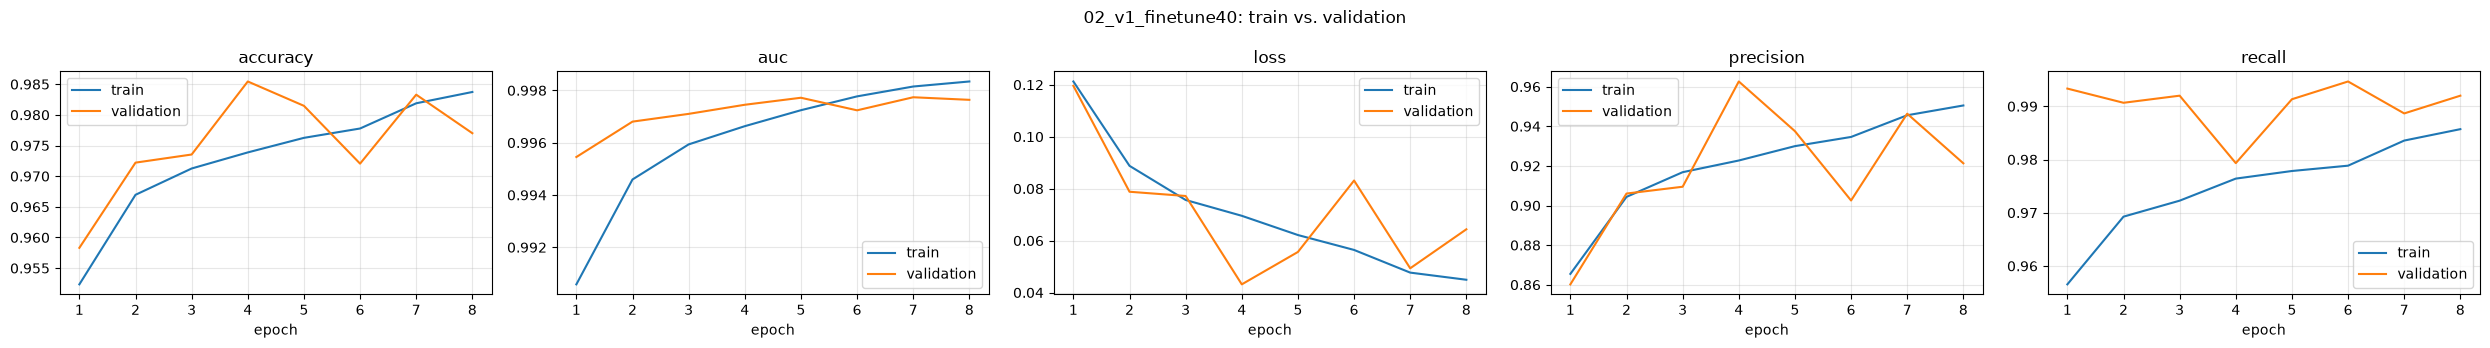

,accuracy,precision,recall,f1,roc_auc
train,0.991,0.975,0.989,0.982,1.000
val,0.985,0.963,0.979,0.971,0.998


,n,accuracy,predicted_photo
category,,,
Painting,1499,97.1%,2.9%
Photo,1499,97.9%,97.9%
Schematics,1336,99.0%,1.0%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [43]:
run_v1f, p_v1f = v2(name="v1_frozen", hypothesis="E5 recipe (frozen MobileNetV2) on the complete dataset",
                    builder="mobilenet_frozen", epochs=15, lr=1e-3, batch_size=64, early_stopping=True, patience=4)
run_v1, p_v1 = v2(name="v1_finetune40", hypothesis="E6 recipe (fine-tune 40 layers, lr 1e-5) on the complete dataset reaches at least E6's level",
                  builder="mobilenet_finetune", builder_kwargs=dict(from_model=str(run_v1f.dir / "model.keras"), n_layers=40),
                  epochs=15, lr=1e-5, batch_size=32, early_stopping=True, patience=4)

### V2: grayscale augmentation
**Hypothesis.** If 25% of the training images (photos *and* non-photos) are randomly converted to black and white,
colour stops being a shortcut: the model must recognize a photo from its structure (optical blur, sensor noise,
natural textures). Expected result: photo recall on grayscale images close to recall on colour images, with no
loss on the other sources.

def augmentation(seed: int = 42, grayscale: float = 0.0) -> keras.Sequential:
    """Only transformations that keep the class: a flipped/rotated/cropped photo is still a photo.
    (No colour jitter: colour statistics are one of the cues separating photos from paintings.)
    grayscale > 0 converts that fraction of training images to black & white, so the model cannot use
    "has colour => photo" as a shortcut and still recognises old black & white photographs."""
    steps = [
        layers.RandomFlip("horizontal", seed=seed),
        layers.RandomRotation(0.05, seed=seed),
        layers.RandomZoom(0.15, seed=seed),
        layers.RandomTranslation(0.1, 0.1, seed=seed),
    ]
    if grayscale:
        steps.append(layers.RandomGrayscale(factor=grayscale, seed=seed))
    return keras.Sequential(steps, name="augmentation")

[03_v2_gray_frozen] already trained: reusing saved results (RETRAIN=False)


**03_v2_gray_frozen**: 2,259,265 parameters, 15 epochs (early stopping, best epoch 15)

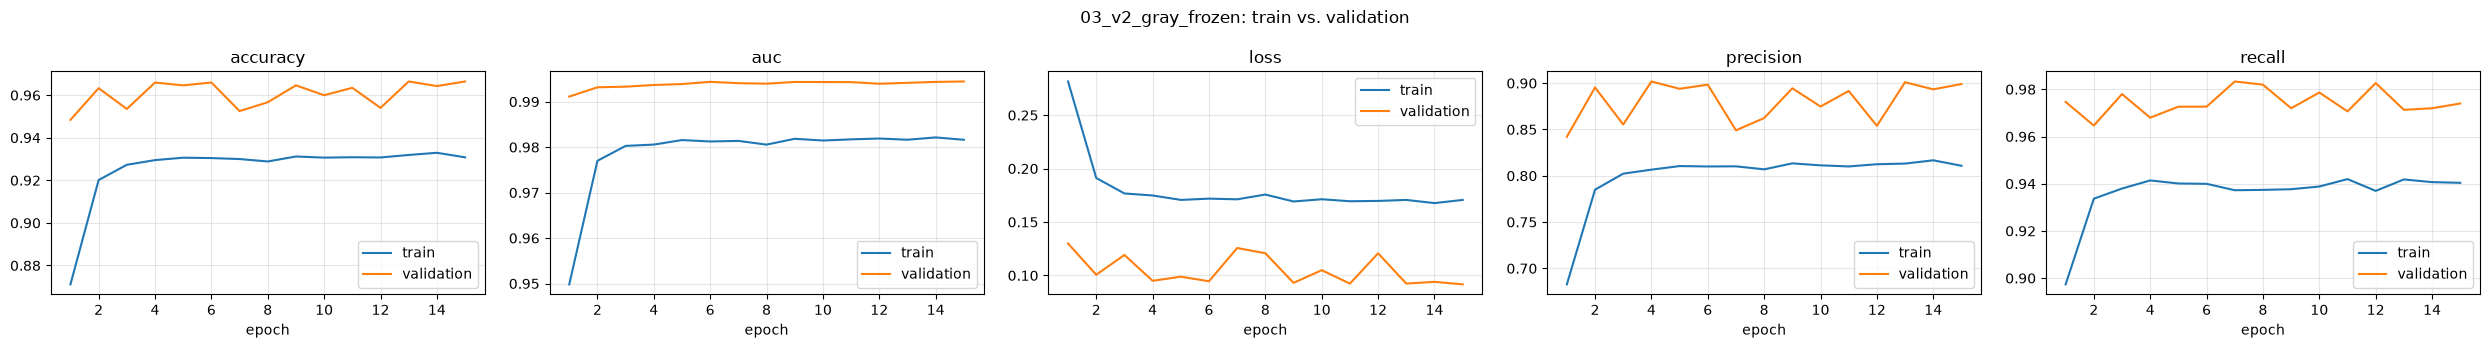

,accuracy,precision,recall,f1,roc_auc
train,0.970,0.908,0.980,0.943,0.995
val,0.966,0.899,0.974,0.935,0.995


,n,accuracy,predicted_photo
category,,,
Painting,1499,92.1%,7.9%
Schematics,1336,96.6%,3.4%
Photo,1499,97.4%,97.4%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


[04_v2_gray_finetune40] already trained: reusing saved results (RETRAIN=False)


**04_v2_gray_finetune40**: 2,259,265 parameters, 11 epochs (early stopping, best epoch 7)

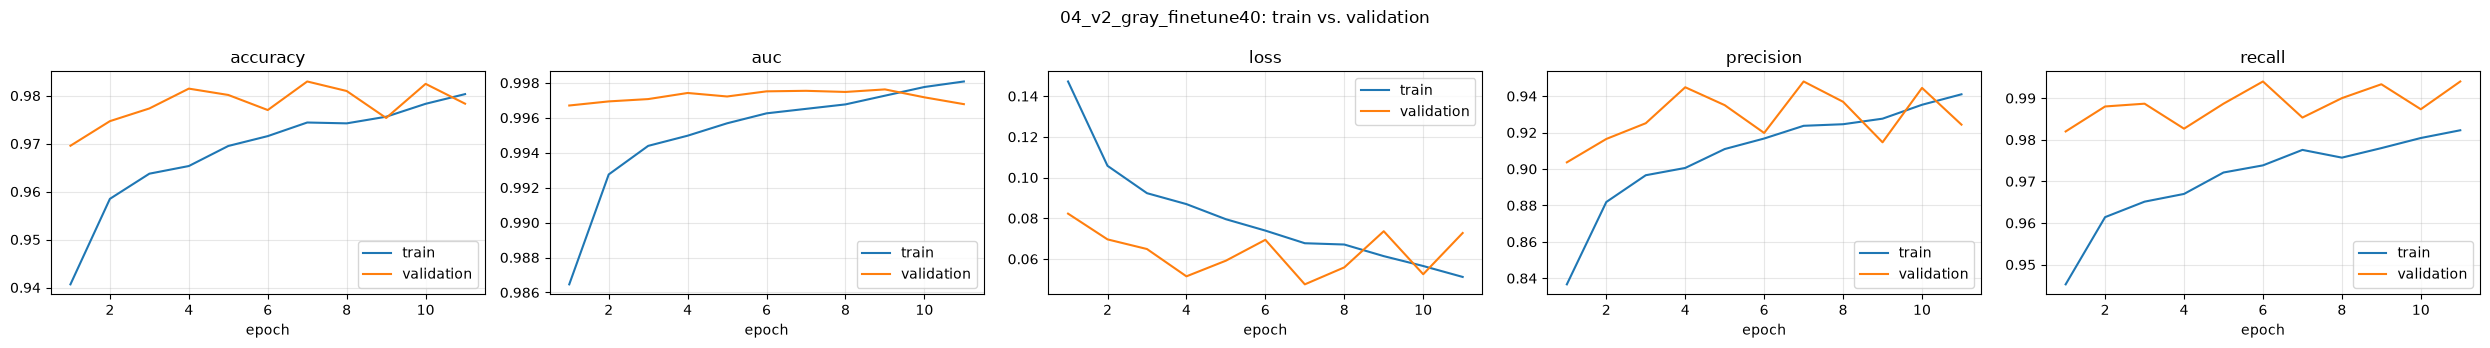

,accuracy,precision,recall,f1,roc_auc
train,0.992,0.971,0.996,0.984,1.000
val,0.983,0.948,0.985,0.966,0.999


,n,accuracy,predicted_photo
category,,,
Painting,1499,95.7%,4.3%
Photo,1499,98.5%,98.5%
Schematics,1336,98.7%,1.3%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [44]:
print(inspect.getsource(M.augmentation))
run_v2f, p_v2f = v2(name="v2_gray_frozen", hypothesis="Frozen MobileNetV2 with 25% random-grayscale augmentation",
                    builder="mobilenet_frozen", builder_kwargs=dict(grayscale=0.25), epochs=15, lr=1e-3, batch_size=64,
                    early_stopping=True, patience=4, augmentation="flip/rot/zoom/translate + grayscale 0.25")
run_v2, p_v2 = v2(name="v2_gray_finetune40", hypothesis="Grayscale augmentation removes the colour shortcut without hurting accuracy",
                  builder="mobilenet_finetune", builder_kwargs=dict(from_model=str(run_v2f.dir / "model.keras"), n_layers=40),
                  epochs=15, lr=1e-5, batch_size=32, early_stopping=True, patience=4,
                  augmentation="flip/rot/zoom/translate + grayscale 0.25")

### V3: a better fine-tuning recipe
**Hypothesis.** Three changes to the *fine-tuning stage only*, starting from V2's frozen model:
* **Label smoothing 0.05**: the targets become 0.975 / 0.025 instead of 1 / 0, so the model is less pushed to be
  100% sure, which suits archives with some wrong labels.
* **60 unfrozen layers** instead of 40: more capacity to adapt to photo vs. painting.
* **ReduceLROnPlateau + patience 5**: the schedule that stabilized E4c.

[05_v3_gray_ls_finetune60] already trained: reusing saved results (RETRAIN=False)


**05_v3_gray_ls_finetune60**: 2,259,265 parameters, 17 epochs (early stopping, best epoch 12)

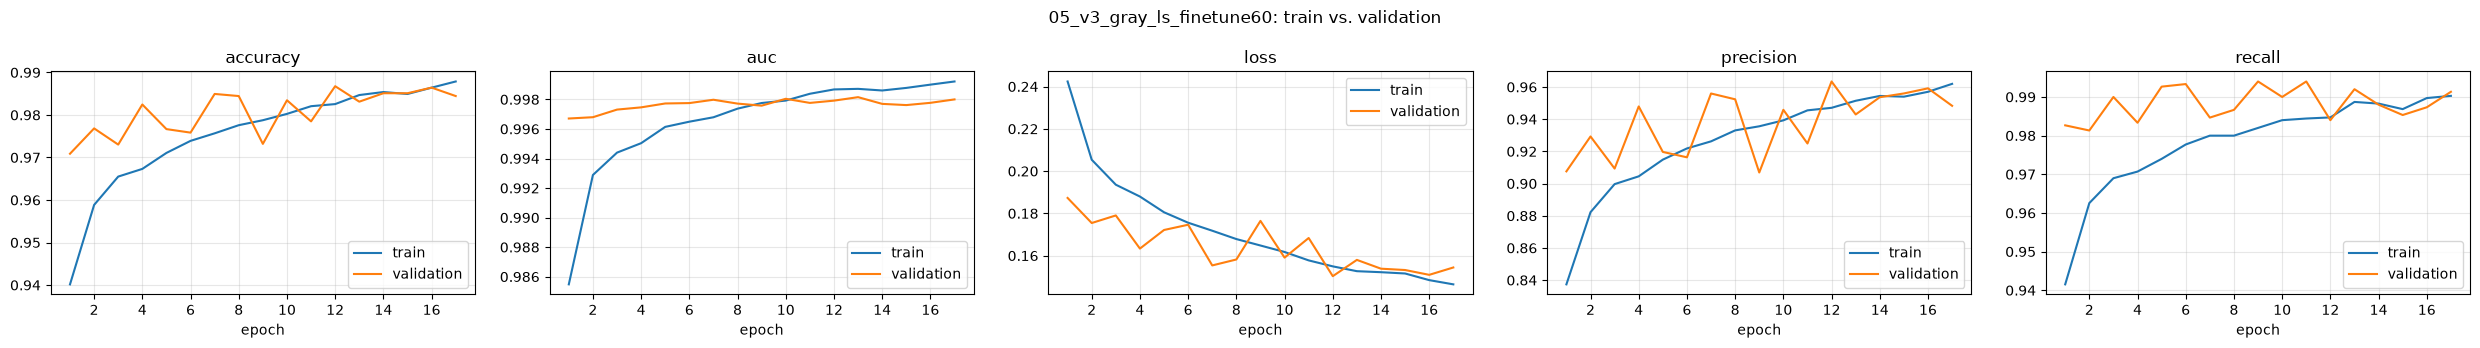

,accuracy,precision,recall,f1,roc_auc
train,0.995,0.981,0.998,0.989,1.000
val,0.987,0.963,0.984,0.974,0.998


,n,accuracy,predicted_photo
category,,,
Painting,1499,97.5%,2.5%
Photo,1499,98.4%,98.4%
Schematics,1336,98.6%,1.4%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [45]:
run_v3, p_v3 = v2(name="v3_gray_ls_finetune60", hypothesis="Label smoothing + 60 unfrozen layers + LR schedule improve on V2",
                  builder="mobilenet_finetune", builder_kwargs=dict(from_model=str(run_v2f.dir / "model.keras"), n_layers=60),
                  epochs=20, lr=1e-5, batch_size=32, early_stopping=True, patience=5, reduce_lr=True, label_smoothing=0.05,
                  augmentation="flip/rot/zoom/translate + grayscale 0.25")

### V4: higher resolution (224 px)
**Hypothesis.** At 160×160 the fine details that separate a photo from a realistic painting (brush strokes,
sensor grain) are partly lost. MobileNetV2's native resolution is 224×224, about 2× more pixels. We benchmarked
it: it fits in the 2 GB GPU at batch 32 (about 1.5× slower per epoch).

[06_v4_gray_frozen_224] already trained: reusing saved results (RETRAIN=False)


**06_v4_gray_frozen_224**: 2,259,265 parameters, 13 epochs (early stopping, best epoch 9)

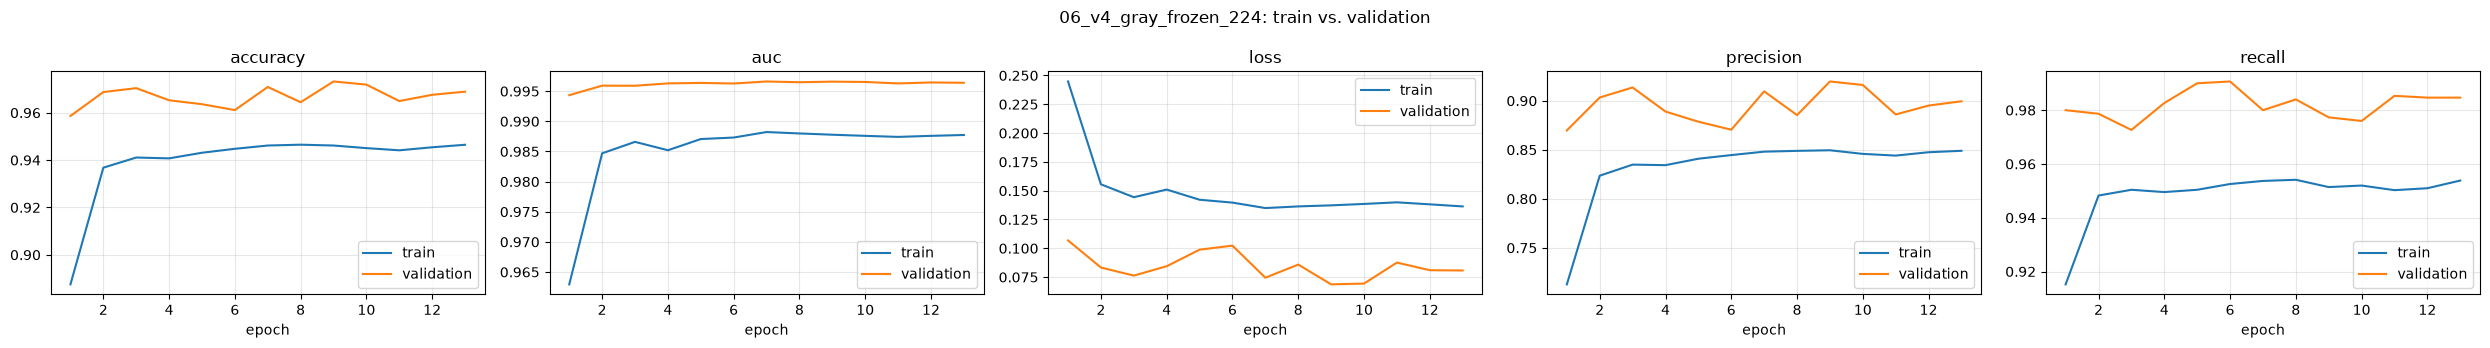

,accuracy,precision,recall,f1,roc_auc
train,0.977,0.931,0.980,0.955,0.997
val,0.973,0.920,0.977,0.948,0.997


,n,accuracy,predicted_photo
category,,,
Painting,1499,94.2%,5.8%
Schematics,1336,96.9%,3.1%
Photo,1499,97.7%,97.7%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


[07_v4_gray_ls_finetune60_224] already trained: reusing saved results (RETRAIN=False)


**07_v4_gray_ls_finetune60_224**: 2,259,265 parameters, 20 epochs (early stopping, best epoch 18)

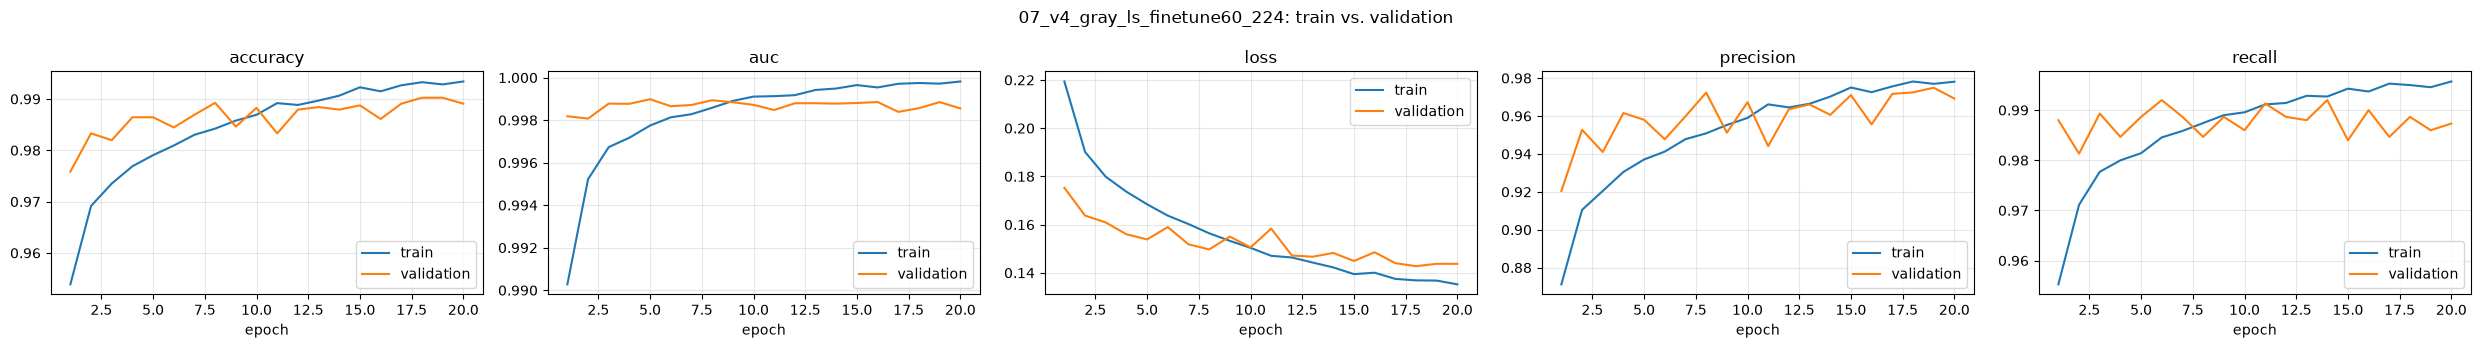

,accuracy,precision,recall,f1,roc_auc
train,0.998,0.994,0.998,0.996,1.000
val,0.990,0.972,0.989,0.980,0.999


,n,accuracy,predicted_photo
category,,,
Painting,1499,97.8%,2.2%
Photo,1499,98.9%,98.9%
Schematics,1336,99.3%,0.7%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [46]:
run_v4f, p_v4f = v2(name="v4_gray_frozen_224", hypothesis="Frozen MobileNetV2 at 224 px with grayscale augmentation",
                    builder="mobilenet_frozen", builder_kwargs=dict(grayscale=0.25), img_size=224, epochs=15, lr=1e-3,
                    batch_size=64, early_stopping=True, patience=4, augmentation="flip/rot/zoom/translate + grayscale 0.25")
run_v4, p_v4 = v2(name="v4_gray_ls_finetune60_224", hypothesis="V3's recipe at 224 px improves on realistic paintings",
                  builder="mobilenet_finetune", builder_kwargs=dict(from_model=str(run_v4f.dir / "model.keras"), n_layers=60),
                  img_size=224, epochs=20, lr=1e-5, batch_size=32, early_stopping=True, patience=5, reduce_lr=True,
                  label_smoothing=0.05, augmentation="flip/rot/zoom/translate + grayscale 0.25")

## 13b. Our own models on the complete dataset (trained from scratch)

The project asks to **train our own network** and compare it with a pre-trained one on accuracy **and** time and
resource consumption. Two from-scratch models are trained on exactly the same data as V1–V4:

* **O1: our best part-1 recipe (E4c):** the plain regularized CNN, dropout 0.4, no L2, learning-rate schedule.
* **O2: our own modern architecture, a small ResNet.** Each *residual block* adds its input to its output
  (`output = F(x) + x`). Gradients can flow straight through these shortcuts, which is what lets deep networks
  train from scratch. 20 convolution layers, 2.8 M parameters, the same scale as MobileNetV2 (2.26 M), so the
  comparison is fair.

Both use the same training settings: augmentation, class weights, learning rate 1e-3 halved on plateau,
early-stopping patience 10, at most 40 epochs.

[08_own_cnn_e4c_recipe] already trained: reusing saved results (RETRAIN=False)


**08_own_cnn_e4c_recipe**: 1,175,393 parameters, 34 epochs (early stopping, best epoch 24)

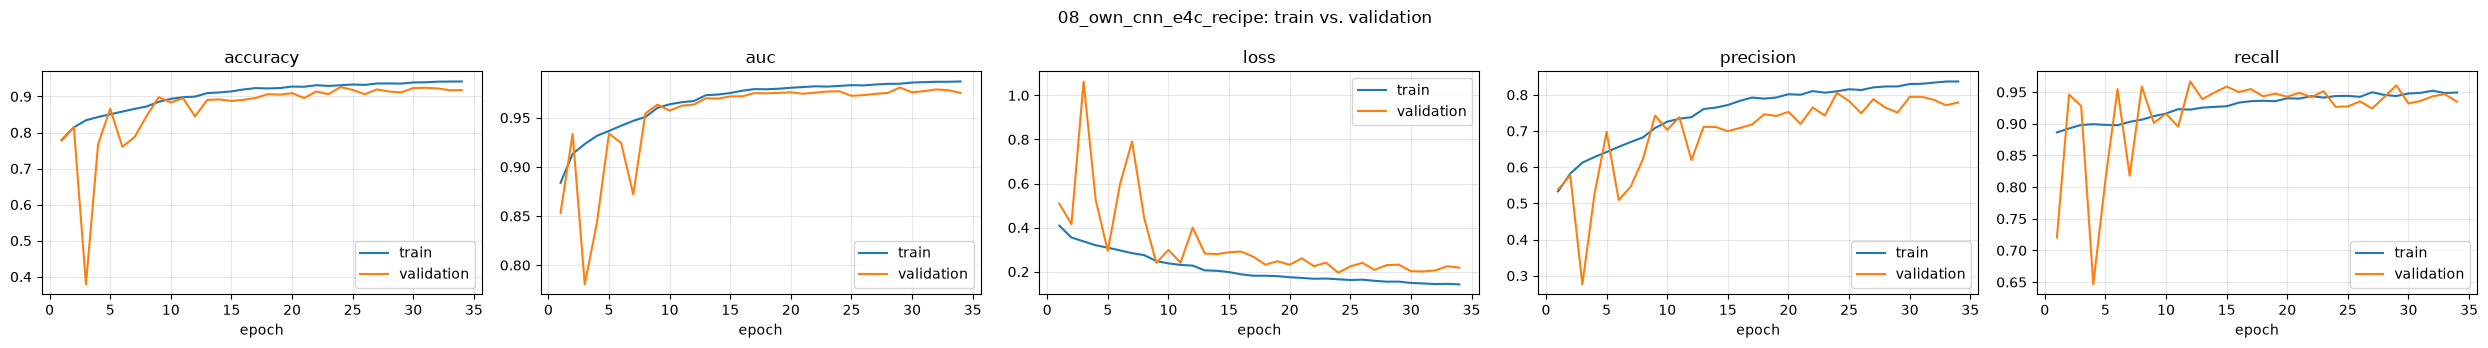

,accuracy,precision,recall,f1,roc_auc
train,0.929,0.803,0.945,0.869,0.984
val,0.926,0.805,0.927,0.862,0.979


,n,accuracy,predicted_photo
category,,,
Painting,1499,81.5%,18.5%
Photo,1499,92.7%,92.7%
Schematics,1336,95.7%,4.3%
Sketch,211,99.5%,0.5%
Text,1500,100.0%,0.0%


[09_own_resnet] already trained: reusing saved results (RETRAIN=False)


**09_own_resnet**: 2,800,097 parameters, 40 epochs (early stopping, best epoch 37)

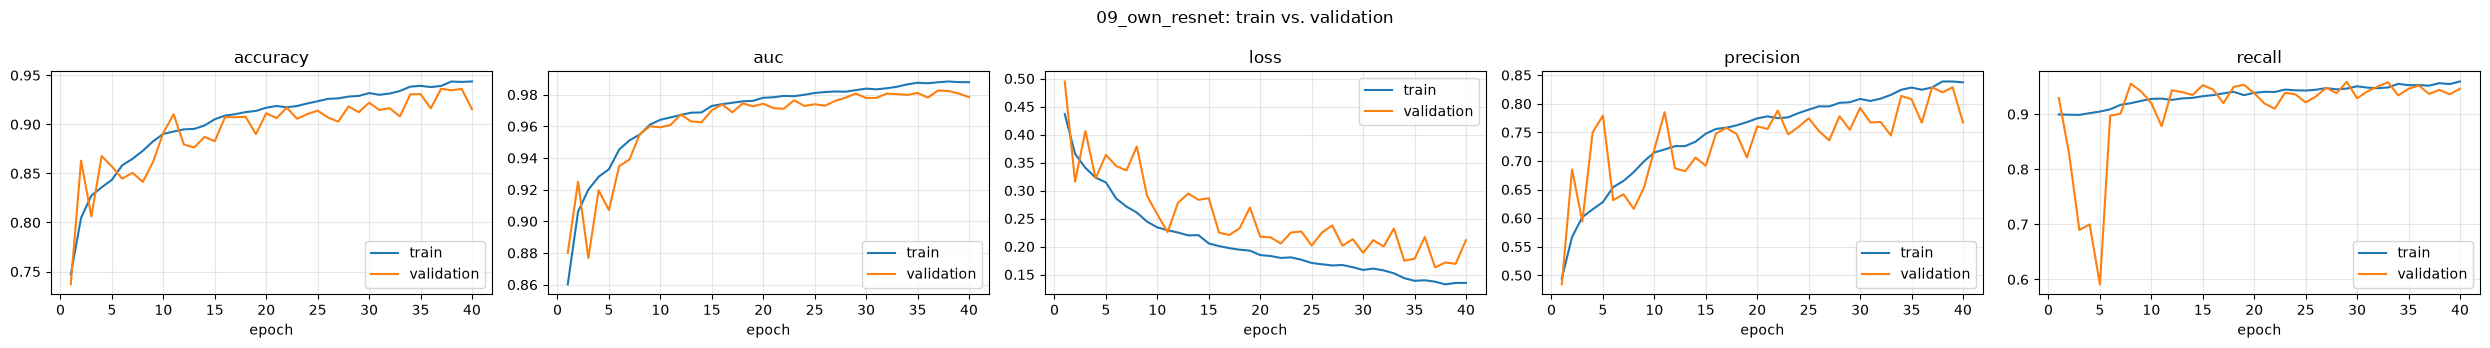

,accuracy,precision,recall,f1,roc_auc
train,0.947,0.844,0.963,0.900,0.990
val,0.936,0.829,0.937,0.879,0.983


,n,accuracy,predicted_photo
category,,,
Painting,1499,83.8%,16.2%
Photo,1499,93.7%,93.7%
Schematics,1336,96.5%,3.5%
Sketch,211,100.0%,0.0%
Text,1500,100.0%,0.0%


In [47]:
own_kw = dict(epochs=40, lr=1e-3, batch_size=32, early_stopping=True, patience=10, reduce_lr=True,
              augmentation="flip/rot/zoom/translate")
run_o1, p_o1 = v2(name="own_cnn_e4c_recipe", builder="regularized_cnn", builder_kwargs=dict(dropout=0.4, l2=0.0),
                  hypothesis="Our best part-1 from-scratch recipe (E4c) on the complete dataset: fair comparison with transfer learning",
                  **own_kw)
run_o2, p_o2 = v2(name="own_resnet", builder="residual_cnn", builder_kwargs=dict(dropout=0.4),
                  hypothesis="A modern from-scratch architecture (small ResNet, 2.8M params, comparable to MobileNetV2) closes part of the gap",
                  **own_kw)

def residual_cnn(img_size: int = 160, widths=(32, 64, 128, 256), blocks_per_stage: int = 2,
                 dropout: float = 0.4, l2: float = 0.0, grayscale: float = 0.0) -> keras.Model:
    """Our own modern from-scratch architecture: a small ResNet (stem + 4 stages of residual blocks,
    each stage halving the resolution and doubling the width, then global average pooling).
    20 convolution layers (17 in the main path + 3 shortcut projections), a depth that plain stacks like
    regularized_cnn can't train reliably."""
    inp = keras.Input((img_size, img_size, 3), name="image")
    x = augmentation(grayscale=grayscale)(inp)
    x = layers.Rescaling(1 / 255)(x)
    x = layers.Conv2D(widths[0], 3, strides=2, padding="same", use_bias=False)(x)  # stem: 160 -> 80 px
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    for i, w in enumerate(widths):
        for b in range(blocks_per_stage):
            x = _residual_block(x, w, stride=2 if (b == 0 and i > 0

/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 126 variables whereas the saved optimizer has 130 variables. 
  saveable.load_own_variables(store)


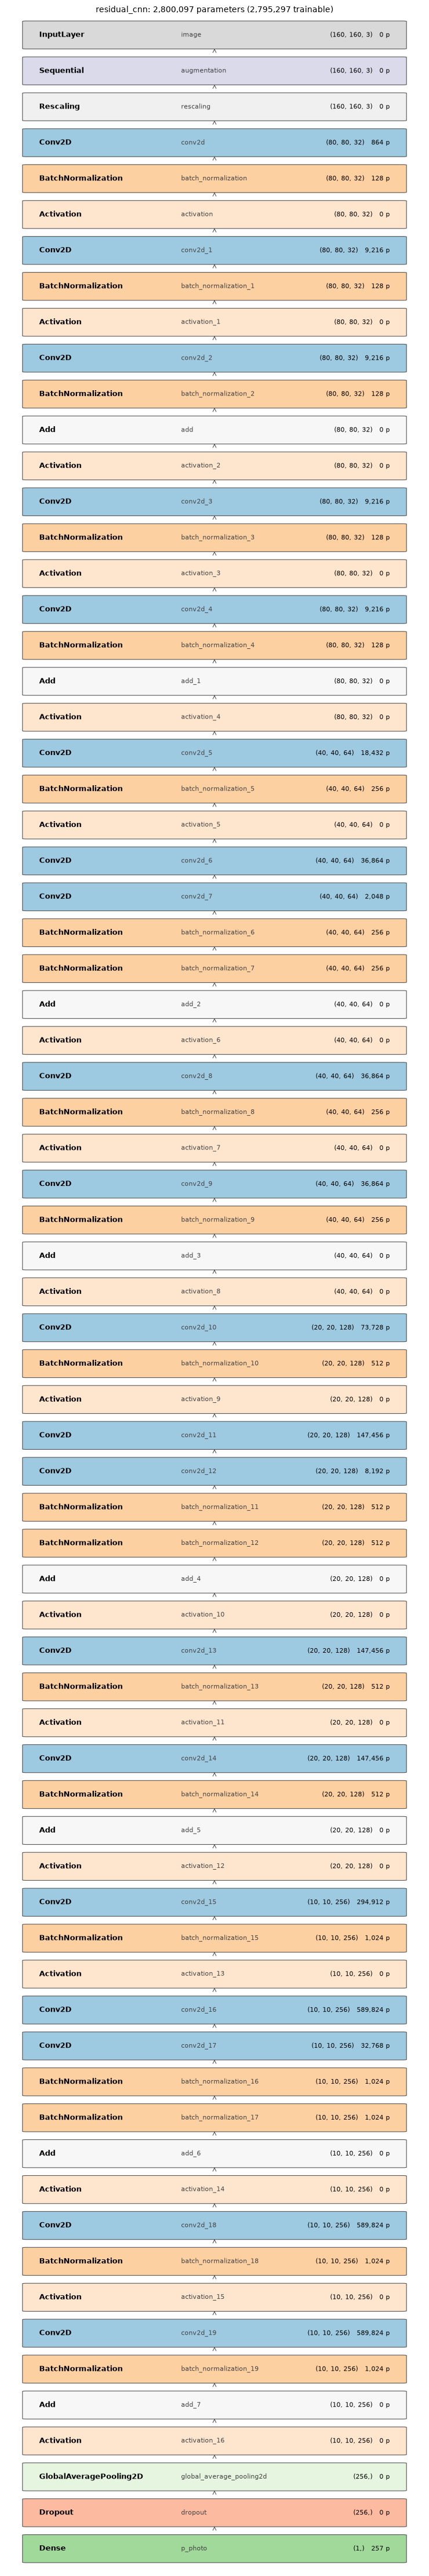

def _residual_block(x, filters: int, stride: int, l2: float):
    """Two 3x3 convolutions + a shortcut that adds the block's input to its output (He et al., ResNet).
    The shortcut lets gradients flow straight through, which makes deeper networks trainable from scratch."""
    reg = regularizers.l2(l2) if l2 else None
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False, kernel_regularizer=reg)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_regularizer=reg)(y)
    y = layers.BatchNormalization()(y)
    if stride != 1 or shortcut.shape[-1] != filters:  # projection when the shape changes
        shortcut = layers.Conv2D(filters, 1, strides=stride, use_bias=False, kernel_regularizer=reg)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    return layers.Activation("relu")(layers.Add()([y, shortcut]))



In [48]:
show_architecture(run_o2, M.residual_cnn)
print(inspect.getsource(M._residual_block))

## 13c. Own vs. pre-trained: accuracy, time and resources

`leyenda.benchmark` scores every model on **the same fixed set**: the 4,523 validation images that **no model ever
trained on**, in part 1 or part 2 (`data.fixed_benchmark`). It also measures size, speed and memory on the GPU
and on the CPU (a production server may have no GPU). Training time for transfer models = frozen stage +
fine-tuning stage.

,family,params (M),trained params (M),file (MB),train time (min),inference GPU (img/s),inference CPU (img/s),accuracy (fixed set),"errors / 4,523"
E4c own CNN (part 1 data),own (from scratch),1.18,1.17,23.7,42,760,60,89.87%,458
E6 MobileNetV2 (part 1 data),pre-trained,2.26,1.66,36.3,9,672,117,96.90%,140
"O1 own CNN, E4c recipe",own (from scratch),1.18,1.17,23.7,49,703,64,90.38%,435
O2 own ResNet,own (from scratch),2.80,2.80,56.3,45,821,118,91.75%,373
V1 MobileNetV2,pre-trained,2.26,1.66,36.3,13,621,111,98.19%,82
V2 + grayscale,pre-trained,2.26,1.66,36.3,10,609,112,97.83%,98
"V3 + LS, 60 layers, LR schedule",pre-trained,2.26,1.93,40.6,14,622,118,98.32%,76
V4 = V3 at 224 px,pre-trained,2.26,1.93,40.6,33,491,55,98.78%,55


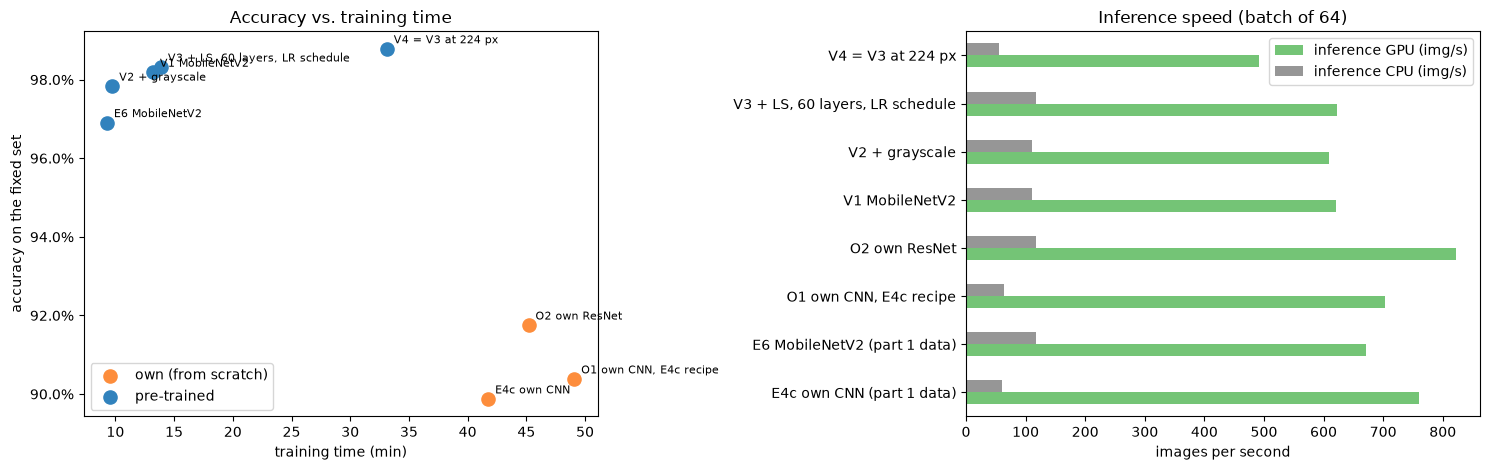

In [49]:
import os
BENCH = RUNS_DIR / "benchmark"
fixed = fixed_benchmark(data, data2)
models_bench = [("E4c own CNN (part 1 data)", "d1_classifier", "reg_d04_l2_0_lr_schedule"),
                ("E6 MobileNetV2 (part 1 data)", "d1_classifier", "mobilenetv2_finetuned"),
                ("O1 own CNN, E4c recipe", D2, "own_cnn_e4c_recipe"), ("O2 own ResNet", D2, "own_resnet"),
                ("V1 MobileNetV2", D2, "v1_finetune40"), ("V2 + grayscale", D2, "v2_gray_finetune40"),
                ("V3 + LS, 60 layers, LR schedule", D2, "v3_gray_ls_finetune60"), ("V4 = V3 at 224 px", D2, "v4_gray_ls_finetune60_224")]
def run_path(deliverable, name):
    return sorted((RUNS_DIR / deliverable).glob(f"[0-9][0-9]_{name}"))[-1]
if not ((BENCH / "gpu.csv").exists() and (BENCH / "cpu.csv").exists()):   # measured once, in separate processes
    BENCH.mkdir(exist_ok=True)
    fixed[["path", "label", "category"]].to_csv(DATA_DIR / "processed" / "d1_fixed_benchmark.csv", index=False)
    spec = {"models": [{"label": l, "run_dir": str(run_path(d, n))} for l, d, n in models_bench],
            "images_csv": str(DATA_DIR / "processed" / "d1_fixed_benchmark.csv")}
    for device in ("gpu", "cpu"):
        env = dict(os.environ, **({"CUDA_VISIBLE_DEVICES": ""} if device == "cpu" else {}))
        subprocess.run([sys.executable, "-m", "leyenda.benchmark", json.dumps({**spec, "out": str(BENCH / f"{device}.csv")})],
                       env=env, check=True)

def train_minutes(run_dir):
    cfg, s = json.loads((run_dir / "config.json").read_text()), json.loads((run_dir / "summary.json").read_text())
    if s.get("train_time_s"):
        return s["train_time_s"] / 60
    return (pd.Timestamp(s["finished"]) - pd.Timestamp(cfg["started"])).total_seconds() / 60   # runs before the epoch timer

parents = {"mobilenetv2_finetuned": ("d1_classifier", "mobilenetv2_frozen"), "v1_finetune40": (D2, "v1_frozen"),
           "v2_gray_finetune40": (D2, "v2_gray_frozen"), "v3_gray_ls_finetune60": (D2, "v2_gray_frozen"),
           "v4_gray_ls_finetune60_224": (D2, "v4_gray_frozen_224")}
gpu, cpu = pd.read_csv(BENCH / "gpu.csv").set_index("label"), pd.read_csv(BENCH / "cpu.csv").set_index("label")
rows = {}
for label, d, n in models_bench:
    minutes = train_minutes(run_path(d, n)) + (train_minutes(run_path(*parents[n])) if n in parents else 0)
    g = gpu.loc[label]
    rows[label] = {"family": "own (from scratch)" if label.startswith(("E4c", "O")) else "pre-trained",
                   "params (M)": g["params"] / 1e6, "trained params (M)": g["trainable_params"] / 1e6, "file (MB)": g["file_mb"],
                   "train time (min)": minutes, "inference GPU (img/s)": g["inference_img_per_s"],
                   "inference CPU (img/s)": cpu.loc[label, "inference_img_per_s"],
                   "accuracy (fixed set)": g["fixed_accuracy"], "errors / 4,523": int(g["fixed_errors"])}
bench = pd.DataFrame(rows).T
bench.to_csv(REPORTS_DIR / "d1_benchmark.csv")
display(bench.style.format({"params (M)": "{:.2f}", "trained params (M)": "{:.2f}", "file (MB)": "{:.1f}",
                            "train time (min)": "{:.0f}", "inference GPU (img/s)": "{:.0f}", "inference CPU (img/s)": "{:.0f}",
                            "accuracy (fixed set)": "{:.2%}"}).highlight_max(subset=["accuracy (fixed set)"], color="#c7e9c0"))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for fam, color in [("own (from scratch)", "#fd8d3c"), ("pre-trained", "#3182bd")]:
    b = bench[bench["family"] == fam]
    ax[0].scatter(b["train time (min)"].astype(float), b["accuracy (fixed set)"].astype(float), s=90, color=color, label=fam)
    for label, r in b.iterrows():
        ax[0].annotate(label.split(" (")[0], (r["train time (min)"], r["accuracy (fixed set)"]), fontsize=8,
                       xytext=(5, 4), textcoords="offset points")
ax[0].set(xlabel="training time (min)", ylabel="accuracy on the fixed set", title="Accuracy vs. training time")
ax[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax[0].legend()
bench[["inference GPU (img/s)", "inference CPU (img/s)"]].astype(float).plot.barh(ax=ax[1], color=["#74c476", "#969696"])
ax[1].set(xlabel="images per second", title="Inference speed (batch of 64)")
plt.tight_layout(); plt.savefig(REPORTS_DIR / "figures" / "d1_own_vs_pretrained.png", dpi=110); plt.show()

**Analysis: own models vs. pre-trained models** (same 4,523 never-seen images).

| | Best own model (O2, ResNet) | Best pre-trained (V4) |
|---|---|---|
| Errors | 373 (91.8%) | **55 (98.8%)** |
| Training time | 45 min | 33 min (V1–V3: 10–14 min) |
| Inference GPU / CPU | **821 / 118 img/s** | 491 / 55 img/s |
| Trained parameters | 2.80 M (all) | 1.93 M (of 2.26 M) |

1. **Our architecture choice mattered.** The ResNet (O2) beats our plain CNN (O1): 373 vs. 435 errors (−14%), with
   about half the training GPU memory (528 vs. 1,008 MB) and almost twice the CPU speed. Skip connections let
   a deeper network train well from scratch.
2. **Pre-trained wins on accuracy by a wide margin:** V1 already makes **4.5× fewer errors** than our best own
   model (82 vs. 373), V4 almost 7× fewer. Our networks learn *everything* from 28,000 images; MobileNetV2 starts
   from features learned on 1.4 million images.
3. **Pre-trained is also cheaper to train:** at 160 px, 10–14 min vs. 45–49 min. Most of its weights are frozen
   and it converges in fewer epochs (the fine-tuning stage stops after 8–20 epochs).
4. **Speed vs. accuracy:** our ResNet is the fastest at inference, and V4's 224 px input costs half the speed of
   V1–V3. For TouNum: V4 when accuracy matters most; V3 (2× faster on CPU, 21 more errors per 4,523 images) for
   very large archives on CPU-only servers.

*Note:* V2 and V3 share a frozen stage that was interrupted and resumed before the epoch timer existed, so their
times are slightly under-counted. Every run since has its exact time (`train_time_s`).

In [50]:
run_o1.annotate("failure", "Best part-1 own recipe on complete data: 435 errors / 4,523 (90.4%), 49 min: from-scratch training can't match transfer learning")
run_o2.annotate("improvement", "Own ResNet: 373 errors (-14% vs O1), fastest inference (821 img/s GPU, 118 CPU), half the training memory; still 4.5x more errors than V1")

## 14. Comparison (validation) and the grayscale check

We compare on **validation** and also check each model on the **validation photos converted to grayscale**,
which shows whether grayscale augmentation did its job *before* we touch the test set.

/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 32 variables whereas the saved optimizer has 36 variables. 
  saveable.load_own_variables(store)


/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 46 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(store)


,img,train acc,val acc,gap,val F1,val AUC,photo recall (colour),photo recall (grayscale)
V1 E6 recipe,160,0.991,0.985,0.006,0.971,0.998,0.979,0.959
V2 + grayscale aug.,160,0.992,0.983,0.009,0.966,0.999,0.985,0.970
"V3 + label smoothing, 60 layers, LR schedule",160,0.995,0.987,0.008,0.974,0.998,0.984,0.971
V4 = V3 at 224 px,224,0.998,0.990,0.008,0.980,0.999,0.989,0.985


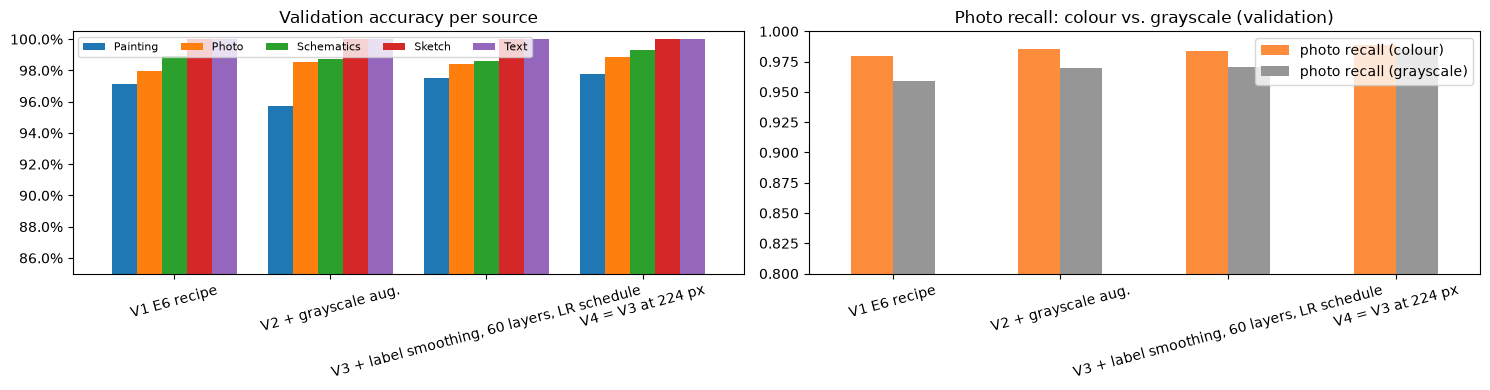

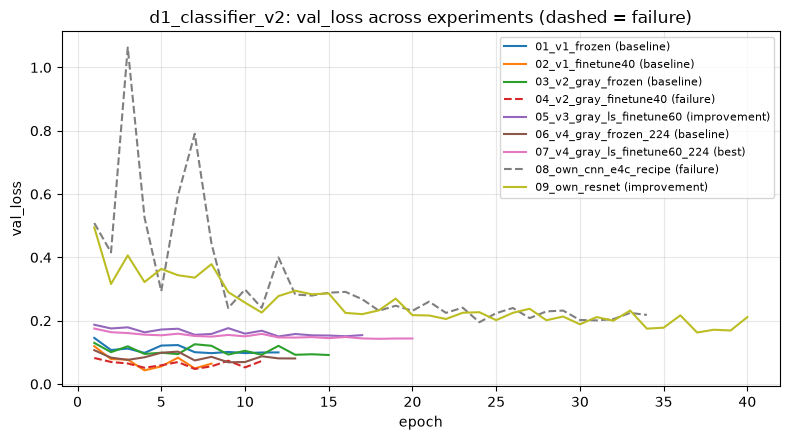

In [51]:
def run_img_size(run):
    return json.loads((run.dir / "config.json").read_text())["img_size"]

@tf.autograph.experimental.do_not_convert
def to_grayscale(x, y):
    gray = tf.image.rgb_to_grayscale(tf.cast(x, tf.float32))
    return tf.cast(tf.image.grayscale_to_rgb(gray), tf.uint8), y

runs2 = {"V1 E6 recipe": (run_v1, p_v1), "V2 + grayscale aug.": (run_v2, p_v2),
         "V3 + label smoothing, 60 layers, LR schedule": (run_v3, p_v3), "V4 = V3 at 224 px": (run_v4, p_v4)}
val2_photos = val2[val2["label"] == 1]
rows2 = {}
for label, (run, probs) in runs2.items():
    ev, size = run.summary()["eval_metrics"], run_img_size(run)
    model = run.load_model()
    p_gray = predict(model, make_dataset(val2_photos, size, VAL_BS).map(to_grayscale))
    rows2[label] = {"img": size, "train acc": ev["train_accuracy"], "val acc": ev["val_accuracy"],
                    "gap": ev["train_accuracy"] - ev["val_accuracy"], "val F1": ev["val_f1"], "val AUC": ev["val_roc_auc"],
                    "photo recall (colour)": ev["val_recall"], "photo recall (grayscale)": float((p_gray >= 0.5).mean())}
comparison2 = pd.DataFrame(rows2).T
display(comparison2.style.format({"img": "{:.0f}", **{c: "{:.3f}" for c in comparison2.columns if c != "img"}})
        .highlight_max(subset=["val F1", "val AUC", "photo recall (grayscale)"], color="#c7e9c0"))

per_source2 = pd.DataFrame({label: per_category_report(val2, probs)["accuracy"] for label, (_, probs) in runs2.items()})
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
per_source2.T.plot.bar(ax=ax[0], width=0.8, ylim=(0.85, 1.005), title="Validation accuracy per source")
ax[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax[0].legend(ncol=5, fontsize=8)
comparison2[["photo recall (colour)", "photo recall (grayscale)"]].plot.bar(ax=ax[1], ylim=(0.8, 1.0), color=["#fd8d3c", "#969696"],
                                                                          title="Photo recall: colour vs. grayscale (validation)")
for a in ax: a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(REPORTS_DIR / "figures" / "d1_v2_comparison.png", dpi=110); plt.show()
plot_runs(D2, "val_loss", save_to=REPORTS_DIR / "figures" / "d1_v2_val_loss.png")

**Analysis: choosing the final model (validation only).**

| Run | Val acc | Val F1 | Photo recall, colour | Photo recall, **grayscale** | Verdict |
|---|---|---|---|---|---|
| V1 (reference) | 98.5% | 0.971 | 97.9% | 95.9% | reference |
| V2 + grayscale aug. | 98.3% | 0.966 | 98.5% | 97.0% | **mixed**: grayscale recall +1.1 pt, F1 −0.005 |
| V3 + LS, 60 layers, LR schedule | 98.7% | 0.974 | 98.4% | 97.1% | **improvement** on V2 and V1 |
| **V4 = V3 at 224 px** | **99.0%** | **0.980** | **98.9%** | **98.5%** | **best**: selected |

* **V2 did its job on the target problem** (grayscale photo recall 95.9% → 97.0%) but cost a little overall F1:
  colour is a legitimate cue, and hiding it on 25% of the images made the task slightly harder. That's why
  augmentation *strength* matters.
* **V3 recovered and passed V1:** the better fine-tuning recipe (label smoothing, more trainable layers, learning-rate
  schedule) more than compensated.
* **V4 is best on every column.** 224 px gives the fine details (brush strokes, sensor grain) that separate
  realistic paintings from photos, and its grayscale recall (98.5%) is almost equal to its colour recall: **the
  colour shortcut is gone**. It used all 20 epochs without early stopping, so it may still improve with longer
  training.
* Every model's train/validation gap stays under 1 point: none of them overfits.

In [52]:
run_v1.annotate("baseline", "E6 recipe on complete data: F1 0.971, 82 errors on fixed set (E6: 141) -> new reference")
run_v2.annotate("failure", "Grayscale aug: grayscale photo recall 95.9 -> 97.0% (goal reached) but F1 0.966 < V1 0.971")
run_v3.annotate("improvement", "LS + 60 layers + LR schedule from V2 frozen: F1 0.974, 76 errors on fixed set; best at 160 px")
run_v4.annotate("best", "V3 at 224 px: val acc 99.0%, F1 0.980, grayscale recall 98.5%; test acc 99.09%")

## 15. Final model: threshold, test set (used once) and robustness

/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 46 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(store)


selected model: V4 = V3 at 224 px (224 px)
threshold chosen on validation (max F1): 0.664


Corrupt JPEG data: 419 extraneous bytes before marker 0xd9


,accuracy,precision,recall,f1,roc_auc
threshold 0.5,0.9896,0.9693,0.9893,0.9792,0.9978
threshold 0.66,0.9909,0.9794,0.9840,0.9817,0.9978


,n,accuracy,predicted_photo
category,,,
Photo,1499,98.40%,98.40%
Painting,1500,98.40%,1.60%
Schematics,1336,99.48%,0.52%
Sketch,211,100.00%,0.00%
Text,1500,100.00%,0.00%


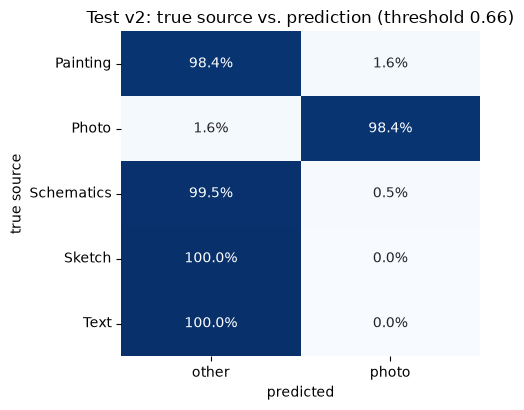

,photo recall (colour),photo recall (grayscale),drop
threshold 0.50,98.9%,98.4%,0.5%
threshold 0.66,98.4%,98.0%,0.4%


In [53]:
best2_label = comparison2["val F1"].idxmax()
best2_run, best2_val_probs = runs2[best2_label]
best2_model, IMG2 = best2_run.load_model(), run_img_size(best2_run)
print("selected model:", best2_label, f"({IMG2} px)")

prec2, rec2, thr2 = precision_recall_curve(val2["label"], best2_val_probs)
f1_2 = 2 * prec2 * rec2 / np.clip(prec2 + rec2, 1e-9, None)
THRESHOLD2 = float(thr2[np.argmax(f1_2[:-1])])
print(f"threshold chosen on validation (max F1): {THRESHOLD2:.3f}")

test2_probs = predict(best2_model, make_dataset(test2, IMG2, VAL_BS))
final2 = pd.DataFrame({"threshold 0.5": binary_metrics(test2["label"], test2_probs, 0.5),
                       f"threshold {THRESHOLD2:.2f}": binary_metrics(test2["label"], test2_probs, THRESHOLD2)}).T
display(final2.style.format("{:.4f}").set_caption(f"Test set v2 ({len(test2):,} images): {best2_label}"))
display(per_category_report(test2, test2_probs, THRESHOLD2).style.format({"accuracy": "{:.2%}", "predicted_photo": "{:.2%}"}))
plot_confusion(test2, test2_probs, THRESHOLD2, title=f"Test v2: true source vs. prediction (threshold {THRESHOLD2:.2f})")

test2_photos = test2[test2["label"] == 1]
pc = predict(best2_model, make_dataset(test2_photos, IMG2, VAL_BS))
pg = predict(best2_model, make_dataset(test2_photos, IMG2, VAL_BS).map(to_grayscale))
stress2 = pd.DataFrame({f"threshold {t:.2f}": {"photo recall (colour)": (pc >= t).mean(), "photo recall (grayscale)": (pg >= t).mean()}
                        for t in (0.5, THRESHOLD2)}).T
stress2["drop"] = stress2.iloc[:, 0] - stress2.iloc[:, 1]
display(stress2.style.format("{:.1%}").set_caption("Grayscale stress test on the test photos"))

**The most confident mistakes on the test set:**

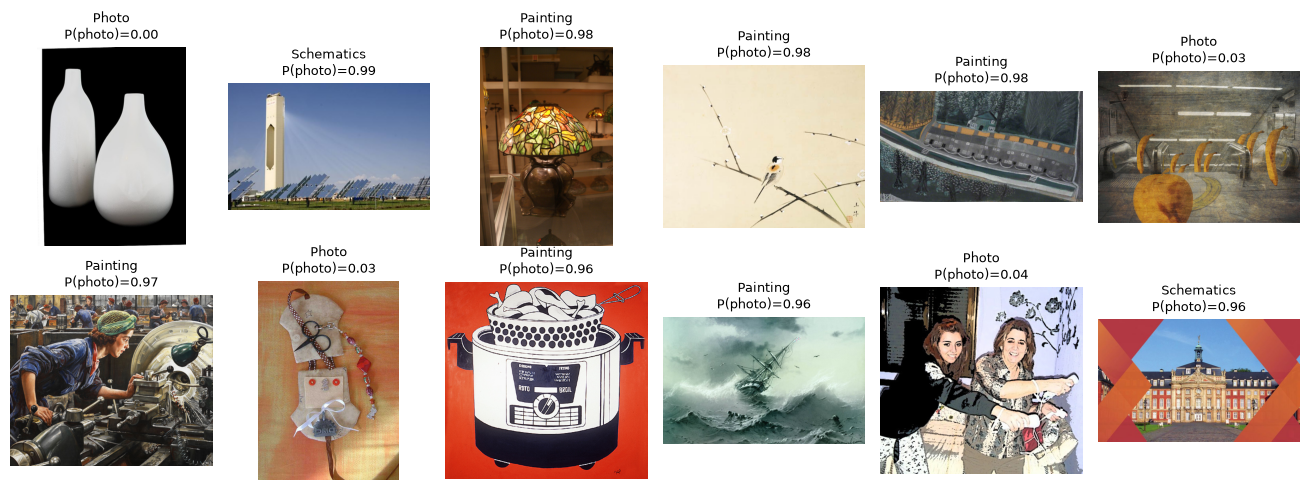

In [54]:
plot_errors(test2, test2_probs, THRESHOLD2, n=12)

**Analysis: final results (test set used once, 6,046 images).**

* **Accuracy 99.09%** (threshold 0.66 chosen on validation), precision 97.9%, recall 98.4%, F1 0.982, AUC 0.998.
  Very close to validation (99.0%), so the model choice did not overfit the validation set.
* **Per source:** Text and Sketch **100%**, Schematics 99.5%, Paintings 98.4% (1.6% accepted as photos), Photos
  98.4% recall.
* **Colour shortcut fixed:** photo recall on grayscale test photos 98.0% vs. 98.4% in colour (a **0.4-point** drop)
  against a **4.3-point** drop for E6 in part 1.
* **Remaining errors:** mostly realistic paintings and unusual photos. As shown by the error analysis
  (`reports/d1_v1_error_analysis.csv`), part of them are **wrong or ambiguous folder labels** (photos filed as
  schematics or paintings, figures made of photos). They are kept as they are: test labels are never changed to
  improve the score.

**From part 1 to part 2:** test accuracy 97.9% (E6) → **99.1% (V4)**, an error rate of 2.1% → 0.9%. The two
test sets differ, so this compares rates; the like-for-like comparison is the fixed set in §13c (140 → 55 errors).

## 16. Training journal (part 2)

In [55]:
display(Markdown(training_journal(D2)))

# Training journal: d1_classifier_v2

## 01_v1_frozen: **BASELINE**
- **Hypothesis:** E5 recipe (frozen MobileNetV2) on the complete dataset
- **Config:** `{"builder": "mobilenet_frozen", "builder_kwargs": {}, "epochs": 15, "lr": 0.001, "batch_size": 64, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 4, "split_file": "d1_split_v2.csv"}`
- **Evaluation:** val_accuracy=0.9636, val_precision=0.8864, val_recall=0.9787, val_f1=0.9302, val_roc_auc=0.9948, train_accuracy=0.9684, train_precision=0.8978, train_recall=0.9845, train_f1=0.9392, train_roc_auc=0.9959
- **Train/val loss gap:** -0.0429 (best val epoch 8/12)
- **Lesson / next step:** Intermediate stage (frozen MobileNetV2), starting point of V1's fine-tuning; same AUC as E5 frozen, threshold shifted by the new class balance

## 02_v1_finetune40: **BASELINE**
- **Hypothesis:** E6 recipe (fine-tune 40 layers, lr 1e-5) on the complete dataset reaches at least E6's level
- **Config:** `{"builder": "mobilenet_finetune", "builder_kwargs": {"from_model": "/home/utilisateur/Bureau/DataScienceA5/runs/d1_classifier_v2/01_v1_frozen/model.keras", "n_layers": 40}, "epochs": 15, "lr": 1e-05, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 4, "split_file": "d1_split_v2.csv"}`
- **Evaluation:** val_accuracy=0.9854, val_precision=0.9626, val_recall=0.9793, val_f1=0.9709, val_roc_auc=0.9984, train_accuracy=0.9911, train_precision=0.9753, train_recall=0.9893, train_f1=0.9822, train_roc_auc=0.9996
- **Train/val loss gap:** 0.0194 (best val epoch 4/8)
- **Lesson / next step:** E6 recipe on complete data: F1 0.971, 82 errors on fixed set (E6: 141) -> new reference

## 03_v2_gray_frozen: **BASELINE**
- **Hypothesis:** Frozen MobileNetV2 with 25% random-grayscale augmentation
- **Config:** `{"builder": "mobilenet_frozen", "builder_kwargs": {"grayscale": 0.25}, "epochs": 15, "lr": 0.001, "batch_size": 64, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 4, "split_file": "d1_split_v2.csv", "augmentation": "flip/rot/zoom/translate + grayscale 0.25"}`
- **Evaluation:** val_accuracy=0.9664, val_precision=0.8990, val_recall=0.9740, val_f1=0.9350, val_roc_auc=0.9947, train_accuracy=0.9705, train_precision=0.9083, train_recall=0.9797, train_f1=0.9427, train_roc_auc=0.9955
- **Train/val loss gap:** -0.0790 (best val epoch 15/15)
- **Lesson / next step:** Intermediate stage, starting point of V2 and V3; better than V1 frozen (192 vs 206 errors on the fixed set)

## 04_v2_gray_finetune40: **FAILURE**
- **Hypothesis:** Grayscale augmentation removes the colour shortcut without hurting accuracy
- **Config:** `{"builder": "mobilenet_finetune", "builder_kwargs": {"from_model": "/home/utilisateur/Bureau/DataScienceA5/runs/d1_classifier_v2/03_v2_gray_frozen/model.keras", "n_layers": 40}, "epochs": 15, "lr": 1e-05, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 4, "split_file": "d1_split_v2.csv", "augmentation": "flip/rot/zoom/translate + grayscale 0.25"}`
- **Evaluation:** val_accuracy=0.9830, val_precision=0.9480, val_recall=0.9853, val_f1=0.9663, val_roc_auc=0.9986, train_accuracy=0.9917, train_precision=0.9710, train_recall=0.9964, train_f1=0.9835, train_roc_auc=0.9998
- **Train/val loss gap:** 0.0216 (best val epoch 7/11)
- **Lesson / next step:** Grayscale aug: grayscale photo recall 95.9 -> 97.0% (goal reached) but F1 0.966 < V1 0.971

## 05_v3_gray_ls_finetune60: **IMPROVEMENT**
- **Hypothesis:** Label smoothing + 60 unfrozen layers + LR schedule improve on V2
- **Config:** `{"builder": "mobilenet_finetune", "builder_kwargs": {"from_model": "/home/utilisateur/Bureau/DataScienceA5/runs/d1_classifier_v2/03_v2_gray_frozen/model.keras", "n_layers": 60}, "epochs": 20, "lr": 1e-05, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 5, "split_file": "d1_split_v2.csv", "reduce_lr": true, "label_smoothing": 0.05, "augmentation": "flip/rot/zoom/translate + grayscale 0.25"}`
- **Evaluation:** val_accuracy=0.9868, val_precision=0.9634, val_recall=0.9840, val_f1=0.9736, val_roc_auc=0.9979, train_accuracy=0.9947, train_precision=0.9812, train_recall=0.9976, train_f1=0.9894, train_roc_auc=0.9999
- **Train/val loss gap:** 0.0080 (best val epoch 12/17)
- **Lesson / next step:** LS + 60 layers + LR schedule from V2 frozen: F1 0.974, 76 errors on fixed set; best at 160 px

## 06_v4_gray_frozen_224: **BASELINE**
- **Hypothesis:** Frozen MobileNetV2 at 224 px with grayscale augmentation
- **Config:** `{"builder": "mobilenet_frozen", "builder_kwargs": {"grayscale": 0.25}, "epochs": 15, "lr": 0.001, "batch_size": 64, "img_size": 224, "train_sources": null, "early_stopping": true, "patience": 4, "split_file": "d1_split_v2.csv", "augmentation": "flip/rot/zoom/translate + grayscale 0.25"}`
- **Evaluation:** val_accuracy=0.9732, val_precision=0.9196, val_recall=0.9773, val_f1=0.9476, val_roc_auc=0.9968, train_accuracy=0.9770, train_precision=0.9309, train_recall=0.9797, train_f1=0.9547, train_roc_auc=0.9972
- **Train/val loss gap:** -0.0556 (best val epoch 9/13)
- **Lesson / next step:** Intermediate stage at 224 px, starting point of V4; best frozen stage (155 errors on the fixed set)

## 07_v4_gray_ls_finetune60_224: **BEST**
- **Hypothesis:** V3's recipe at 224 px improves on realistic paintings
- **Config:** `{"builder": "mobilenet_finetune", "builder_kwargs": {"from_model": "/home/utilisateur/Bureau/DataScienceA5/runs/d1_classifier_v2/06_v4_gray_frozen_224/model.keras", "n_layers": 60}, "epochs": 20, "lr": 1e-05, "batch_size": 32, "img_size": 224, "train_sources": null, "early_stopping": true, "patience": 5, "split_file": "d1_split_v2.csv", "reduce_lr": true, "label_smoothing": 0.05, "augmentation": "flip/rot/zoom/translate + grayscale 0.25"}`
- **Evaluation:** val_accuracy=0.9902, val_precision=0.9724, val_recall=0.9887, val_f1=0.9805, val_roc_auc=0.9986, train_accuracy=0.9979, train_precision=0.9941, train_recall=0.9976, train_f1=0.9958, train_roc_auc=1.0000
- **Train/val loss gap:** 0.0085 (best val epoch 18/20)
- **Lesson / next step:** V3 at 224 px: val acc 99.0%, F1 0.980, grayscale recall 98.5%; test acc 99.09%

## 08_own_cnn_e4c_recipe: **FAILURE**
- **Hypothesis:** Our best part-1 from-scratch recipe (E4c) on the complete dataset: fair comparison with transfer learning
- **Config:** `{"builder": "regularized_cnn", "builder_kwargs": {"dropout": 0.4, "l2": 0.0}, "epochs": 40, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 10, "split_file": "d1_split_v2.csv", "reduce_lr": true, "augmentation": "flip/rot/zoom/translate"}`
- **Evaluation:** val_accuracy=0.9262, val_precision=0.8052, val_recall=0.9266, val_f1=0.8617, val_roc_auc=0.9788, train_accuracy=0.9291, train_precision=0.8034, train_recall=0.9452, train_f1=0.8686, train_roc_auc=0.9840
- **Train/val loss gap:** 0.0759 (best val epoch 24/34)
- **Lesson / next step:** Best part-1 own recipe on complete data: 435 errors / 4,523 (90.4%), 49 min: from-scratch training can't match transfer learning

## 09_own_resnet: **IMPROVEMENT**
- **Hypothesis:** A modern from-scratch architecture (small ResNet, 2.8M params, comparable to MobileNetV2) closes part of the gap
- **Config:** `{"builder": "residual_cnn", "builder_kwargs": {"dropout": 0.4}, "epochs": 40, "lr": 0.001, "batch_size": 32, "img_size": 160, "train_sources": null, "early_stopping": true, "patience": 10, "split_file": "d1_split_v2.csv", "reduce_lr": true, "augmentation": "flip/rot/zoom/translate"}`
- **Evaluation:** val_accuracy=0.9363, val_precision=0.8288, val_recall=0.9366, val_f1=0.8794, val_roc_auc=0.9835, train_accuracy=0.9468, train_precision=0.8443, train_recall=0.9631, train_f1=0.8998, train_roc_auc=0.9904
- **Train/val loss gap:** 0.0763 (best val epoch 37/40)
- **Lesson / next step:** Own ResNet: 373 errors (-14% vs O1), fastest inference (821 img/s GPU, 118 CPU), half the training memory; still 4.5x more errors than V1


## 17. Production export

The selected model is saved together with its metadata (threshold, input size). Because pre-processing is built
into the model, TouNum only needs to provide raw image files.

In [56]:
MODELS_DIR.mkdir(exist_ok=True)
best2_model.save(MODELS_DIR / "d1_photo_classifier.keras")
meta = {"model": best2_label, "run": f"{D2}/{best2_run.dir.name}", "img_size": IMG2, "threshold": THRESHOLD2,
        "classes": {"0": "other", "1": "photo"}, "test_metrics": final2.iloc[1].to_dict()}
(MODELS_DIR / "d1_photo_classifier.json").write_text(json.dumps(meta, indent=2))

# --- usage on new files (what module 2 / the full pipeline will call) ---
def filter_photos(paths, model=best2_model, threshold=THRESHOLD2, img_size=IMG2):
    df = pd.DataFrame({"path": list(map(str, paths)), "label": 0})
    df["p_photo"] = predict(model, make_dataset(df, img_size, VAL_BS))
    df["is_photo"] = df["p_photo"] >= threshold
    return df[["path", "p_photo", "is_photo"]]

display(filter_photos(test2.sample(8, random_state=1)["path"]))

,path,p_photo,is_photo
0,/home/utilisateur/Bureau/DataScienceA5/data/ra...,0.973,True
1,/home/utilisateur/Bureau/DataScienceA5/data/ra...,0.023,False
2,/home/utilisateur/Bureau/DataScienceA5/data/ra...,0.162,False
3,/home/utilisateur/Bureau/DataScienceA5/data/ra...,0.969,True
4,/home/utilisateur/Bureau/DataScienceA5/data/ra...,0.025,False
5,/home/utilisateur/Bureau/DataScienceA5/data/ra...,0.014,False
6,/home/utilisateur/Bureau/DataScienceA5/data/ra...,0.959,True
7,/home/utilisateur/Bureau/DataScienceA5/data/ra...,0.034,False
